<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/practica_clasificadores_integrante3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 3: Machine Learning — Integrante 3 Jorge (K-NN + Naïve Bayes)

| Día | Actividad | Secciones |
|---|---|---|
| 3 de noviembre | Preparación de bibliotecas y entorno de trabajo | 1 |
| 4 de noviembre | Datasets, análisis exploratorio y normalización | 2, 3, 4 y 5 |
| 5 de noviembre | K-NN desde cero | 6 |
| 6 de noviembre | Naïve Bayes con Scikit-learn | 7 |
| 7 de noviembre | Pruebas de K-NN y Naïve Bayes en ambos datasets (Hold Out y K-Fold) | 8 |
| 8 de noviembre | Integración de resultados y verificación de divisiones del equipo | 9 |
| 9 de noviembre | Optimización de K-NN | 10 |
| 10 de noviembre | Comparación de los seis clasificadores y complejidad temporal | 11 y 12 |
| 11 de noviembre | Conclusiones | 13 |

> Para usarlo: **Entorno de ejecución → Ejecutar todas**. Cada vez que se abra el notebook, tiene que volver a ejecutarse
> completo, porque Colab borra las variables al desconectarse.

# 1. Preparación del entorno

En esta sección se configura el entorno de trabajo utilizado para desarrollar la práctica de clasificación mediante
algoritmos de Machine Learning.

Se emplea Google Colab como plataforma de ejecución y Python como lenguaje de programación. Asimismo, se importan las
bibliotecas necesarias para la generación, manipulación, visualización y evaluación de los conjuntos de datos, así
como para la implementación de los clasificadores.

Con el propósito de obtener resultados reproducibles y facilitar la comparación entre los integrantes del equipo, se
utilizan configuraciones comunes de experimentación: semilla aleatoria, proporción de entrenamiento y prueba,
número de folds y funciones de evaluación.

## 1.1 Importación de bibliotecas

- **NumPy:** operaciones matemáticas y manipulación de arreglos numéricos.
- **Pandas:** organización y exploración de datos mediante estructuras tabulares.
- **Matplotlib y Seaborn:** gráficas para visualizar la distribución de los datos y los resultados.
- **Time:** medición de los tiempos de ejecución de los algoritmos.
- **Scikit-learn:** generación de datasets, particiones de validación, normalización, métricas y los clasificadores
  que se implementan con biblioteca (Naïve Bayes).

Google Colab ya incluye todas estas bibliotecas, por lo que no es necesario instalarlas con `pip`.

In [1]:
import time
import copy
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import make_classification, load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier   # solo para VALIDAR el K-NN propio
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
print("Entorno preparado correctamente")

Entorno preparado correctamente


## 1.2 Configuración común del equipo

Estos parámetros son los mismos que usa el Integrante 1 en su notebook (`random_state=42`, `test_size=0.30`,
`StratifiedKFold` con 5 folds). Los tres integrantes deben usarlos sin cambios para que las particiones sean
idénticas y los resultados de los seis clasificadores puedan compararse.

In [2]:
SEMILLA   = 42     # semilla común para todo el equipo
TEST_SIZE = 0.30   # Hold Out 70/30
N_FOLDS   = 5      # K-Fold Cross-Validation (k = 5)

np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print(f"Python       {platform.python_version()}")
for nombre, mod in [("numpy", np), ("pandas", pd), ("scikit-learn", sklearn),
                    ("matplotlib", plt.matplotlib), ("seaborn", sns)]:
    print(f"{nombre:<12} {mod.__version__}")

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1
matplotlib   3.10.0
seaborn      0.13.2


## 1.3 Archivo `requirements.txt`

Se genera un archivo con las versiones exactas de las bibliotecas de este entorno. Se sube al repositorio de GitHub
para que cualquier persona pueda reproducir los resultados.

In [3]:
paquetes = {"numpy": np, "pandas": pd, "scikit-learn": sklearn,
            "matplotlib": plt.matplotlib, "seaborn": sns}
with open("requirements.txt", "w") as f:
    for nombre, mod in paquetes.items():
        f.write(f"{nombre}=={mod.__version__}\n")
print(open("requirements.txt").read())

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2



## 1.4 Funciones de evaluación compartidas

Para que los seis clasificadores se midan de la misma forma, el equipo utiliza estas funciones:

- **Hold Out 70/30 estratificado**: conserva la proporción de clases en entrenamiento y prueba.
- **K-Fold estratificado** con `shuffle=True` y la semilla común.
- La **normalización se ajusta solo con los datos de entrenamiento** de cada partición, lo que evita
  *data leakage*.
- Se mide por separado el tiempo de entrenamiento (`fit`) y el de predicción (`predict`).
- Métricas: exactitud, precisión, recall y F1, con promedio *macro* porque hay tres clases.

Funcionan con cualquier modelo que tenga los métodos `fit(X, y)` y `predict(X)`: los clasificadores programados
desde cero (Distancia Mínima, 1-NN y K-NN) y los de Scikit-learn (Naïve Bayes, SVM y MLP).

In [4]:
def calcular_metricas(y_real, y_pred):
    return {
        "exactitud": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "recall":    recall_score(y_real, y_pred, average="macro", zero_division=0),
        "f1":        f1_score(y_real, y_pred, average="macro", zero_division=0),
    }


def dividir_holdout(X, y):
    # Particion Hold Out 70/30 estratificada, identica para todo el equipo
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)


def obtener_kfold():
    return StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)


def _entrenar_y_medir(modelo, X_tr, y_tr, X_te, y_te, escalar):
    modelo = copy.deepcopy(modelo)              # modelo nuevo en cada particion
    if escalar:
        escalador = StandardScaler().fit(X_tr)  # se ajusta SOLO con entrenamiento
        X_tr, X_te = escalador.transform(X_tr), escalador.transform(X_te)
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr)
    t1 = time.perf_counter(); y_pred = modelo.predict(X_te)
    t2 = time.perf_counter()
    res = calcular_metricas(y_te, y_pred)
    res["t_fit_ms"] = (t1 - t0) * 1000
    res["t_pred_ms"] = (t2 - t1) * 1000
    return res, y_pred


def evaluar_holdout(modelo, X, y, escalar=True):
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    X_tr, X_te, y_tr, y_te = dividir_holdout(X, y)
    res, y_pred = _entrenar_y_medir(modelo, X_tr, y_tr, X_te, y_te, escalar)
    return res, (y_te, y_pred)


def evaluar_kfold(modelo, X, y, escalar=True):
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    filas = []
    for tr, te in obtener_kfold().split(X, y):
        res, _ = _entrenar_y_medir(modelo, X[tr], y[tr], X[te], y[te], escalar)
        filas.append(res)
    df = pd.DataFrame(filas)
    resumen = df.mean().to_dict()
    resumen.update({f"{c}_std": df[c].std(ddof=0) for c in ["exactitud", "f1"]})
    return resumen, df

print("Funciones de evaluación listas")

Funciones de evaluación listas


# 2. Datasets

Para evaluar el comportamiento de los clasificadores se utilizan dos conjuntos de datos: uno sintético generado
mediante Scikit-learn y otro real correspondiente al conjunto Wine. Ambos cuentan con tres clases, lo que permite una
comparación consistente entre los clasificadores implementados.

El dataset sintético permite analizar el desempeño de los algoritmos bajo condiciones controladas, mientras que Wine
permite evaluar su comportamiento sobre datos reales con características numéricas de diferente escala.

## 2.1 Dataset sintético con ruido estructurado

Este dataset es el generado por el **Integrante 1**; se usa exactamente el mismo código para que los tres integrantes
trabajen con los mismos datos.

Se construye con `make_classification`: 1,000 muestras, seis características y tres clases. Para simular condiciones
de clasificación menos ideales se introduce un 5 % de etiquetas alteradas (`flip_y`) y se agrega **ruido
correlacionado**: el mismo vector de ruido se suma a las dos primeras características. Como ese ruido afecta a ambas
de la misma forma, no es aleatorio e independiente sino que tiene una estructura, y por eso se considera
**ruido estructurado**.

In [5]:
# Generacion del dataset sintetico (codigo del Integrante 1)
X_sintetico, y_sintetico = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=2,
    n_classes=3,
    n_clusters_per_class=1,
    weights=[0.33, 0.33, 0.34],
    flip_y=0.05,
    class_sep=1.0,
    random_state=SEMILLA
)

X_sintetico_sin_ruido = X_sintetico.copy()   # copia solo para analizar el efecto del ruido

# Ruido correlacionado: el mismo vector se suma a las dos primeras caracteristicas
rng = np.random.default_rng(SEMILLA)
ruido = rng.normal(0, 0.5, size=len(X_sintetico))
X_sintetico[:, 0] += ruido
X_sintetico[:, 1] += ruido

# DataFrame para el analisis exploratorio
df_sintetico = pd.DataFrame(X_sintetico, columns=[f"x{i+1}" for i in range(X_sintetico.shape[1])])
df_sintetico["Clase"] = y_sintetico

print("Dataset sintético generado")
print("Muestras:", X_sintetico.shape[0])
print("Características:", X_sintetico.shape[1])
print("Clases:", np.unique(y_sintetico))
df_sintetico.head()

Dataset sintético generado
Muestras: 1000
Características: 6
Clases: [0 1 2]


,x1,x2,x3,x4,x5,x6,Clase
0,-1.095756,1.088039,-1.357980,0.594635,-0.773984,-1.970431,1
1,0.548328,-2.322018,-1.095786,1.259912,-0.195769,1.388165,2
2,2.499158,-0.693986,-0.030875,1.961111,0.056536,1.435064,2
3,2.026773,-0.528336,-0.220439,1.530983,0.071325,1.106722,2
4,-1.388396,-0.249893,0.037783,-0.386495,-0.938290,-0.245778,0


## 2.2 Parámetros del dataset sintético

| Parámetro | Valor | Explicación |
|---|---|---|
| `n_samples` | 1000 | Número de muestras generadas. |
| `n_features` | 6 | Número total de características por muestra. |
| `n_informative` | 4 | Características que aportan información útil para distinguir las clases. |
| `n_redundant` | 2 | Características que son combinaciones lineales de las informativas. |
| `n_classes` | 3 | Número de clases. |
| `n_clusters_per_class` | 1 | Cada clase se genera como un solo grupo de puntos. |
| `weights` | [0.33, 0.33, 0.34] | Proporción de muestras de cada clase (clases balanceadas). |
| `flip_y` | 0.05 | Aproximadamente 5 % de las etiquetas se asignan al azar (ruido en las etiquetas). |
| `class_sep` | 1.0 | Separación entre clases; valores menores producen más traslape. |
| `random_state` | 42 | Semilla que permite reproducir exactamente el mismo dataset. |
| Ruido correlacionado | $\mathcal{N}(0,\,0.5)$ | Un mismo vector de ruido sumado a `x1` y `x2` (ruido estructurado). |

## 2.3 Carga del dataset real: Wine

El segundo conjunto de datos es Wine, disponible en Scikit-learn y originalmente publicado en el repositorio de
aprendizaje automático de UCI. Contiene 178 muestras de tres clases de vino, descritas por 13 características
numéricas reales asociadas a propiedades químicas, como alcohol, ácido málico, cenizas, alcalinidad y magnesio.

Cumple el requisito de la práctica de un dataset benchmark con al menos 4 rasgos numéricos reales y 3 clases. Además,
sus características tienen escalas muy distintas, lo que lo hace adecuado para analizar la importancia de la
normalización en los algoritmos basados en distancias.

In [6]:
wine = load_wine()
X_wine, y_wine = wine.data, wine.target

df_wine = pd.DataFrame(X_wine, columns=wine.feature_names)
df_wine["Clase"] = y_wine

print("Dataset Wine")
print("Muestras:", X_wine.shape[0])
print("Características:", X_wine.shape[1])
print("Clases:", np.unique(y_wine))
df_wine.head()

Dataset Wine
Muestras: 178
Características: 13
Clases: [0 1 2]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


# 3. Análisis exploratorio de datos

Antes de implementar los clasificadores se realiza un análisis exploratorio de ambos conjuntos de datos con el fin
de:

- Verificar que los datos estén completos (sin valores nulos ni duplicados).
- Conocer la distribución de las clases.
- Comparar las escalas de las características.
- Identificar qué características separan mejor las clases.
- Detectar correlaciones entre características y valores atípicos.

## 3.1 Funciones de análisis

Las funciones son genéricas: reciben cualquier `DataFrame` con una columna `Clase`, por lo que se aplican igual a los
dos datasets.

In [7]:
def resumen_dataset(df, nombre, objetivo="Clase"):
    rasgos = df.drop(columns=objetivo)
    print(f"===== {nombre} =====")
    print(f"Muestras: {df.shape[0]}  |  Características: {rasgos.shape[1]}  |  Clases: {df[objetivo].nunique()}")
    print(f"Valores nulos: {int(df.isnull().sum().sum())}  |  Filas duplicadas: {int(df.duplicated().sum())}")
    conteo = df[objetivo].value_counts().sort_index()
    print("\nDistribución de clases:")
    print(pd.DataFrame({"muestras": conteo, "%": (100 * conteo / len(df)).round(1)}))
    return rasgos.describe().T.round(3)


def graficar_clases(df, nombre, objetivo="Clase"):
    plt.figure(figsize=(5, 3.5))
    sns.countplot(data=df, x=objetivo, color="#4C72B0")
    plt.title(f"Distribución de clases — {nombre}")
    plt.xlabel("Clase"); plt.ylabel("Número de muestras")
    plt.tight_layout(); plt.show()


def graficar_histogramas(df, nombre, objetivo="Clase", columnas=4):
    rasgos = [c for c in df.columns if c != objetivo]
    filas = int(np.ceil(len(rasgos) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3 * filas))
    axes = np.atleast_1d(axes).ravel()
    for ax, r in zip(axes, rasgos):
        sns.histplot(data=df, x=r, hue=objetivo, element="step", stat="density",
                     common_norm=False, palette="Set2", ax=ax, legend=(r == rasgos[0]))
        ax.set_title(r, fontsize=10); ax.set_xlabel("")
    for ax in axes[len(rasgos):]:
        ax.remove()
    fig.suptitle(f"Distribución de cada característica por clase — {nombre}", y=1.01)
    plt.tight_layout(); plt.show()


def graficar_boxplots(df, nombre, objetivo="Clase", titulo_extra=""):
    plt.figure(figsize=(max(8, 0.8 * (df.shape[1] - 1)), 4))
    sns.boxplot(data=df.drop(columns=objetivo), color="#8DA0CB")
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Boxplot de características — {nombre} {titulo_extra}")
    plt.tight_layout(); plt.show()


def graficar_correlacion(df, nombre, objetivo="Clase"):
    corr = df.drop(columns=objetivo).corr()
    n = corr.shape[0]
    plt.figure(figsize=(0.65 * n + 3, 0.55 * n + 2))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                square=True, annot_kws={"size": 7})
    plt.title(f"Matriz de correlación — {nombre}")
    plt.tight_layout(); plt.show()
    pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
                 .sort_values(key=abs, ascending=False))
    print("Pares de características más correlacionados (r):")
    print(pares.head(5).round(3).to_string())


def contar_outliers_iqr(df, objetivo="Clase"):
    # Valores fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
    rasgos = df.drop(columns=objetivo)
    q1, q3 = rasgos.quantile(0.25), rasgos.quantile(0.75)
    iqr = q3 - q1
    fuera = (rasgos < q1 - 1.5 * iqr) | (rasgos > q3 + 1.5 * iqr)
    tabla = pd.DataFrame({"outliers": fuera.sum(), "%": (100 * fuera.mean()).round(1)})
    return tabla[tabla["outliers"] > 0].sort_values("outliers", ascending=False)


def medias_por_clase(df, objetivo="Clase"):
    return df.groupby(objetivo).mean().T.round(3)

## 3.2 Análisis exploratorio — Wine

In [8]:
resumen_dataset(df_wine, "Wine")

===== Wine =====
Muestras: 178  |  Características: 13  |  Clases: 3
Valores nulos: 0  |  Filas duplicadas: 0

Distribución de clases:
       muestras     %
Clase                
0            59  33.1
1            71  39.9
2            48  27.0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


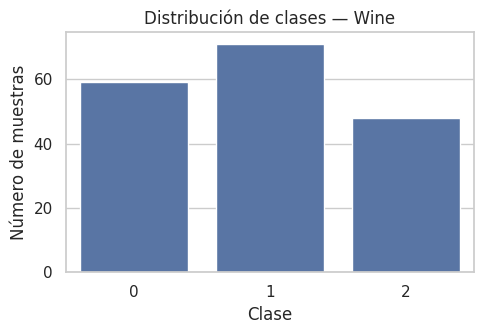

In [9]:
graficar_clases(df_wine, "Wine")

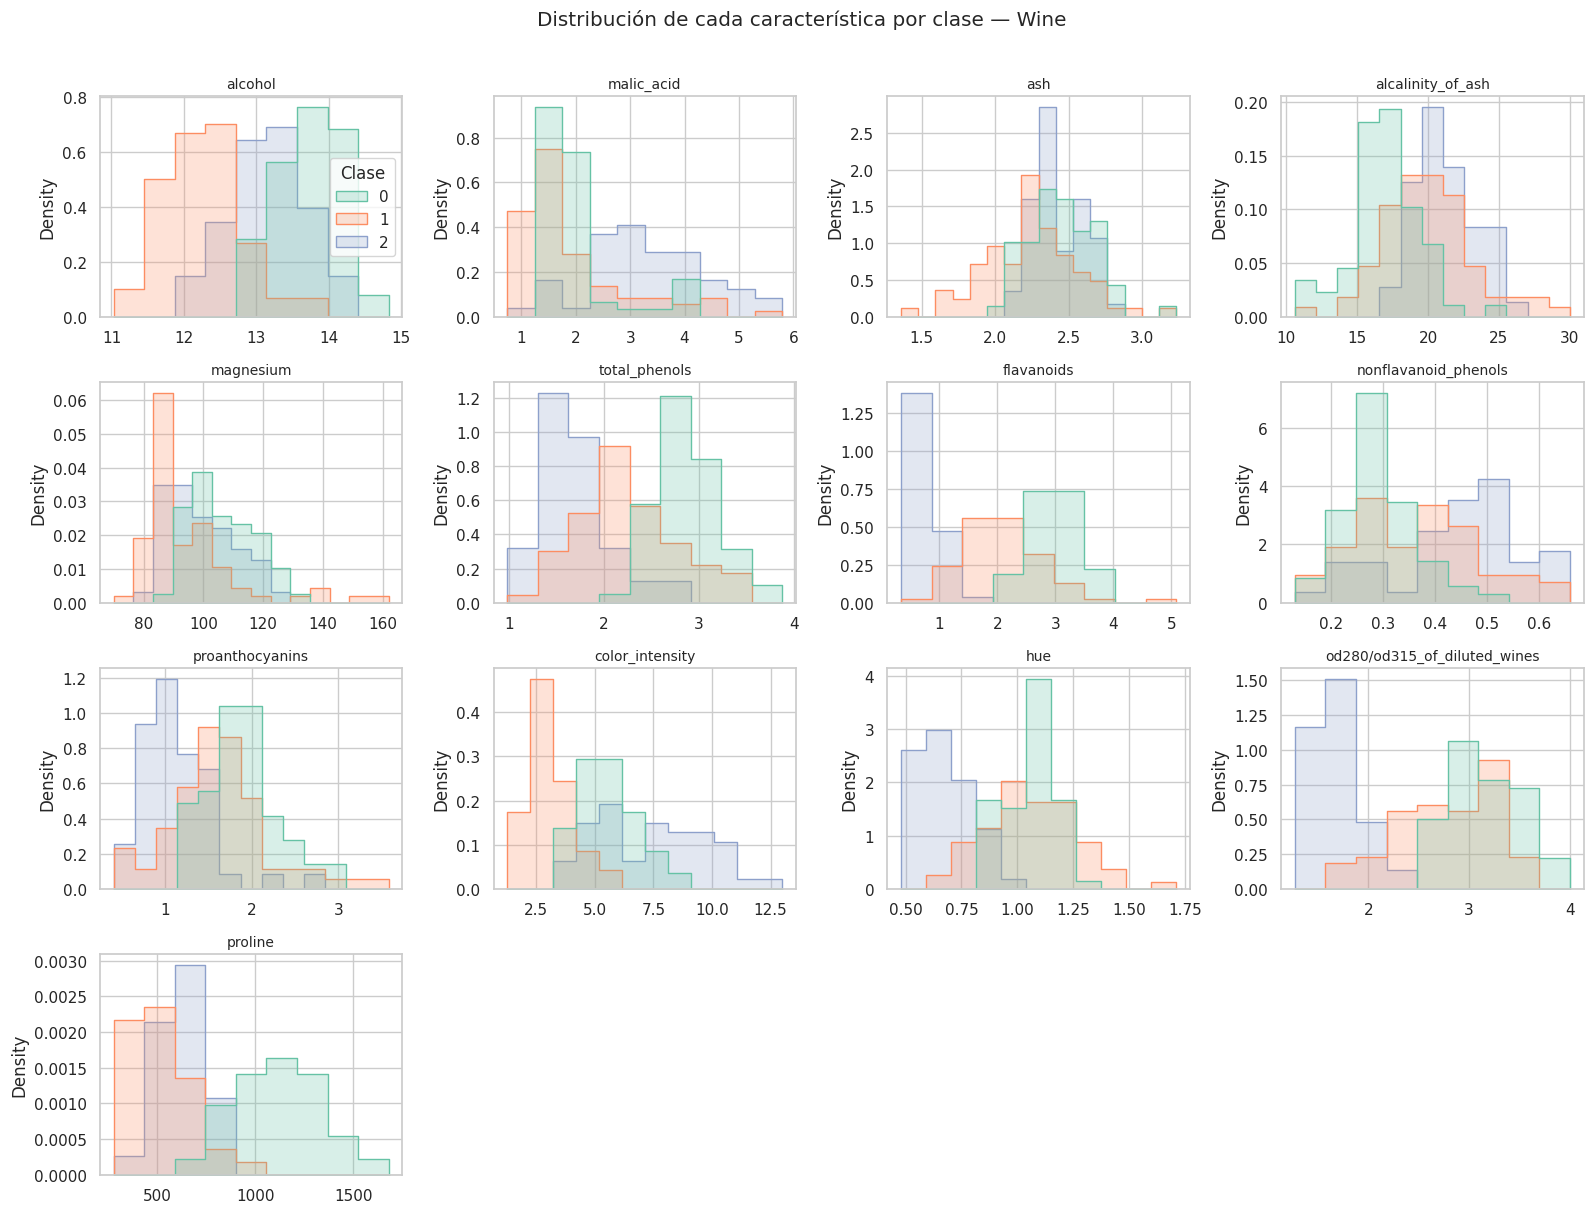

In [10]:
graficar_histogramas(df_wine, "Wine")

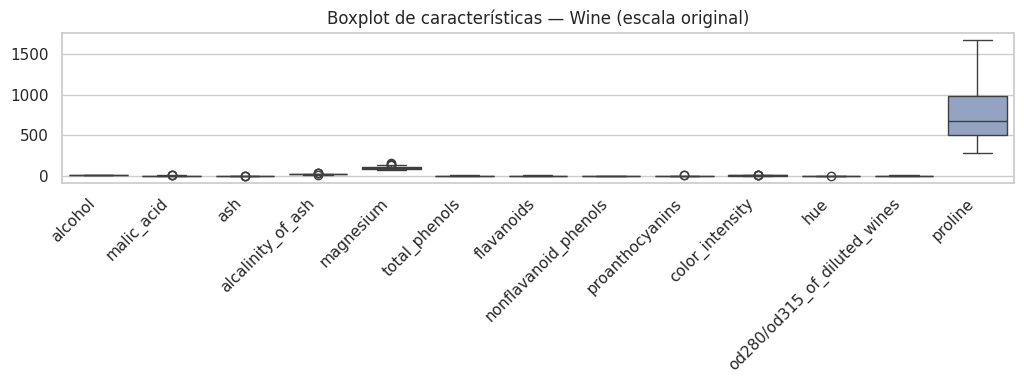

In [11]:
graficar_boxplots(df_wine, "Wine", titulo_extra="(escala original)")

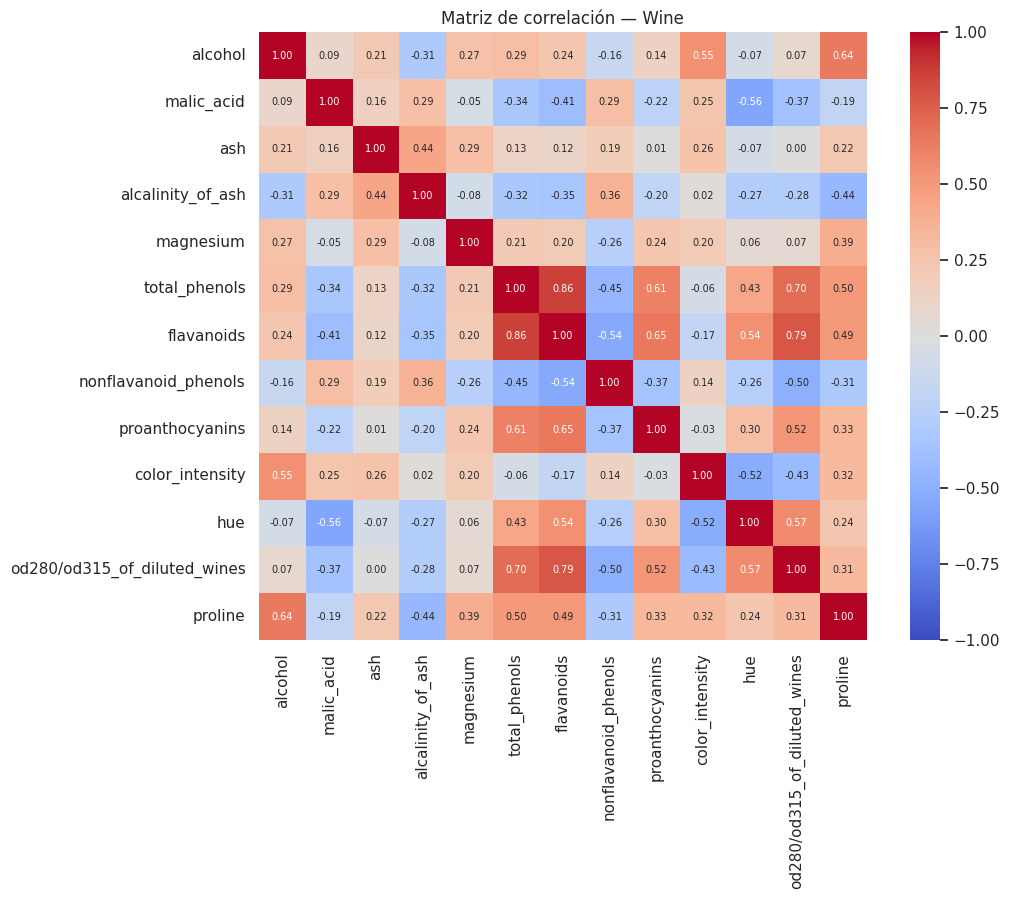

Pares de características más correlacionados (r):
total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
total_phenols  od280/od315_of_diluted_wines    0.700
flavanoids     proanthocyanins                 0.653
alcohol        proline                         0.644


In [12]:
graficar_correlacion(df_wine, "Wine")

In [13]:
contar_outliers_iqr(df_wine)

,outliers,%
alcalinity_of_ash,4,2.2
color_intensity,4,2.2
magnesium,4,2.2
ash,3,1.7
malic_acid,3,1.7
proanthocyanins,2,1.1
hue,1,0.6


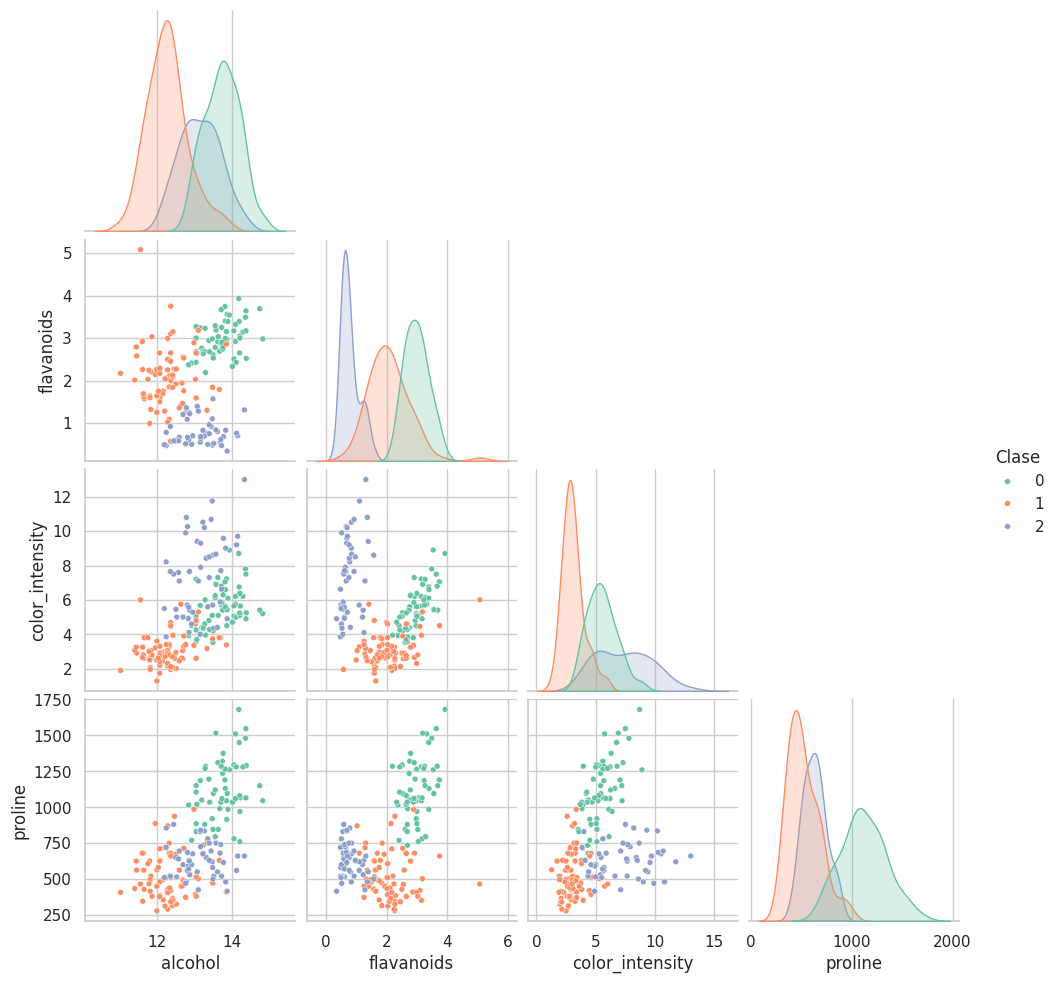

In [14]:
# Vista conjunta de cuatro caracteristicas que separan bien las clases
sns.pairplot(df_wine[["alcohol", "flavanoids", "color_intensity", "proline", "Clase"]],
             hue="Clase", palette="Set2", corner=True, plot_kws={"s": 18})
plt.show()

### Observaciones — Wine

- **Datos completos:** no hay valores nulos ni filas duplicadas, por lo que no se requiere imputación.
- **Clases moderadamente desbalanceadas:** 59, 71 y 48 muestras (33.1 %, 39.9 % y 27.0 %). Por eso las particiones
  se hacen de forma **estratificada**, para conservar estas proporciones en entrenamiento y prueba.
- **Escalas muy diferentes:** `proline` tiene media cercana a 747 y desviación de 315, mientras que `hue` tiene media
  cercana a 0.96 y desviación de 0.23. Sin normalizar, `proline` y `magnesium` dominarían el cálculo de distancias en
  Distancia Mínima, 1-NN y K-NN.
- **Características muy correlacionadas:** `total_phenols` con `flavanoids` (r ≈ 0.86) y `flavanoids` con
  `od280/od315_of_diluted_wines` (r ≈ 0.79). Esto es relevante para Naïve Bayes, que supone independencia entre
  características.
- **Características más discriminantes:** en los histogramas y el pairplot, `flavanoids`, `proline`,
  `color_intensity` y `alcohol` muestran clases claramente separadas, por lo que se espera un buen desempeño general.
- **Pocos valores atípicos:** como máximo 2.2 % por característica (criterio IQR), así que no se eliminan muestras.

## 3.3 Análisis exploratorio — Sintético

In [15]:
resumen_dataset(df_sintetico, "Sintético")

===== Sintético =====
Muestras: 1000  |  Características: 6  |  Clases: 3
Valores nulos: 0  |  Filas duplicadas: 0

Distribución de clases:
       muestras     %
Clase                
0           325  32.5
1           331  33.1
2           344  34.4


,count,mean,std,min,25%,50%,75%,max
x1,1000.0,-0.362,1.743,-5.492,-1.373,-0.371,0.588,5.551
x2,1000.0,0.011,1.475,-5.176,-0.944,-0.014,0.930,5.138
x3,1000.0,-0.956,1.026,-4.595,-1.540,-0.959,-0.348,3.034
x4,1000.0,0.395,1.470,-4.948,-0.322,0.733,1.295,4.230
x5,1000.0,-1.002,1.068,-4.530,-1.666,-0.957,-0.290,2.357
x6,1000.0,-0.271,1.448,-5.274,-1.335,-0.275,0.853,3.880


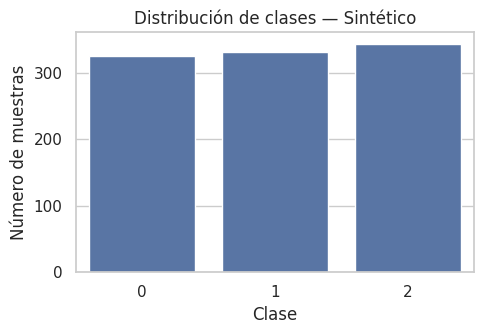

In [16]:
graficar_clases(df_sintetico, "Sintético")

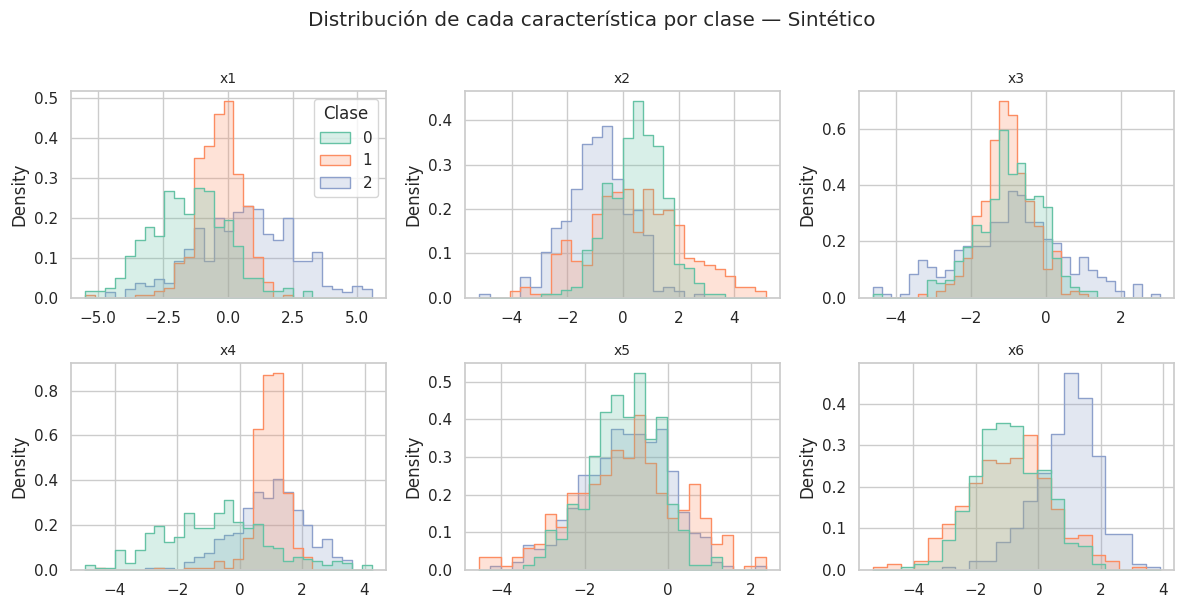

In [17]:
graficar_histogramas(df_sintetico, "Sintético", columnas=3)

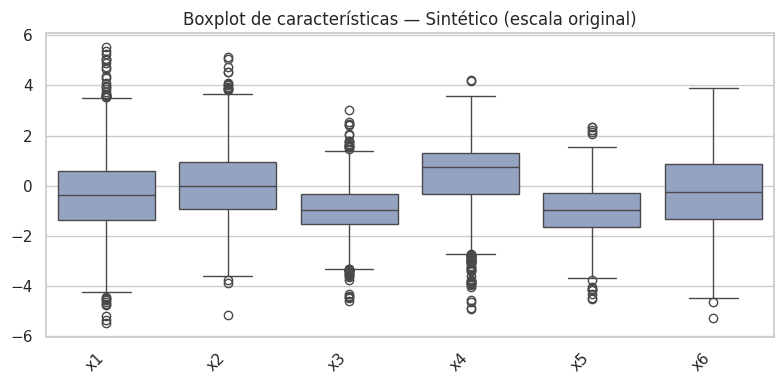

In [18]:
graficar_boxplots(df_sintetico, "Sintético", titulo_extra="(escala original)")

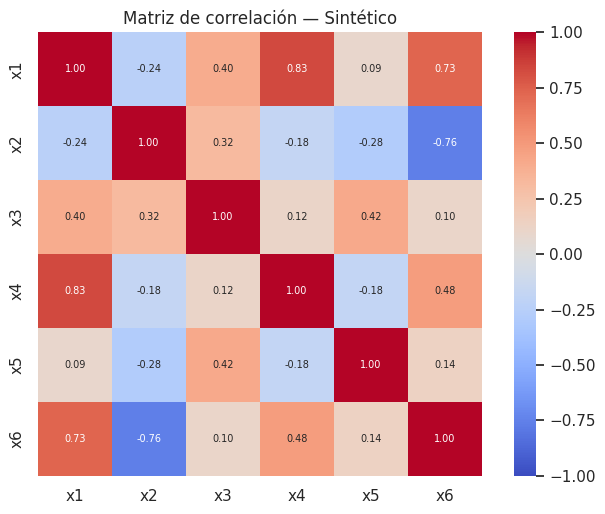

Pares de características más correlacionados (r):
x1  x4    0.834
x2  x6   -0.764
x1  x6    0.728
x4  x6    0.480
x3  x5    0.421


In [19]:
graficar_correlacion(df_sintetico, "Sintético")

In [20]:
contar_outliers_iqr(df_sintetico)

,outliers,%
x4,46,4.6
x3,37,3.7
x1,34,3.4
x2,16,1.6
x5,13,1.3
x6,2,0.2


In [21]:
medias_por_clase(df_sintetico)

Clase,0,1,2
x1,-1.503,-0.305,0.662
x2,0.473,0.478,-0.876
x3,-0.950,-1.028,-0.891
x4,-0.779,0.940,0.980
x5,-1.039,-0.968,-1.000
x6,-0.895,-0.895,0.920


### Efecto del ruido correlacionado

Se compara el dataset antes y después de agregar el ruido para mostrar qué cambia en `x1` y `x2`.

Correlación x1-x2 antes del ruido:   -0.364
Correlación x1-x2 después del ruido: -0.239
Desviación de x1: 1.690 -> 1.743
Desviación de x2: 1.376 -> 1.475


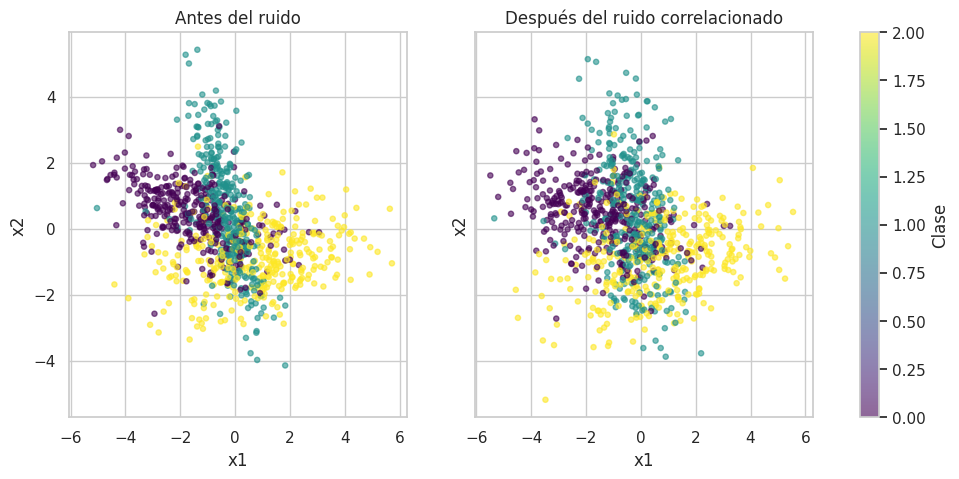

In [22]:
antes = pd.DataFrame(X_sintetico_sin_ruido[:, :2], columns=["x1", "x2"])
despues = df_sintetico[["x1", "x2"]]

print(f"Correlación x1-x2 antes del ruido:   {antes.corr().iloc[0, 1]: .3f}")
print(f"Correlación x1-x2 después del ruido: {despues.corr().iloc[0, 1]: .3f}")
print(f"Desviación de x1: {antes['x1'].std():.3f} -> {despues['x1'].std():.3f}")
print(f"Desviación de x2: {antes['x2'].std():.3f} -> {despues['x2'].std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, datos, titulo in [(axes[0], X_sintetico_sin_ruido, "Antes del ruido"),
                          (axes[1], X_sintetico, "Después del ruido correlacionado")]:
    sc = ax.scatter(datos[:, 0], datos[:, 1], c=y_sintetico, cmap="viridis", alpha=0.6, s=14)
    ax.set_title(titulo); ax.set_xlabel("x1"); ax.set_ylabel("x2")
fig.colorbar(sc, ax=axes, label="Clase")
plt.show()

### Observaciones — Sintético

- **Datos completos y balanceados:** 1,000 muestras sin nulos ni duplicados, con 325, 331 y 344 muestras por clase.
- **Escalas parecidas:** las desviaciones estándar van de 1.0 a 1.7 aproximadamente. A diferencia de Wine, aquí la
  normalización no cambia tanto las escalas relativas, pero se aplica igual para tratar ambos datasets con el mismo
  procedimiento.
- **Características redundantes:** hay correlaciones fuertes, como `x1`–`x4` (r ≈ 0.83), `x2`–`x6` (r ≈ −0.76) y
  `x1`–`x6` (r ≈ 0.73). Son consecuencia de las 2 características redundantes, que son combinaciones lineales de las
  informativas.
- **Características poco discriminantes:** en la tabla de medias por clase, `x3` y `x5` tienen prácticamente la misma
  media en las tres clases, por lo que, vistas por separado, aportan poca información. En cambio, `x1`, `x4`, `x2` y
  `x6` sí cambian de media entre clases.
- **Efecto del ruido estructurado:** como el mismo ruido se suma a `x1` y `x2`, les agrega un componente común que
  empuja su correlación hacia valores positivos: la correlación original de −0.36 se debilita a −0.24. La dispersión
  también aumenta (de 1.69 a 1.74 en `x1` y de 1.38 a 1.48 en `x2`), lo que produce más traslape entre clases en esas
  dos características. El efecto es moderado porque la desviación del ruido (0.5) es menor que la de las
  características (alrededor de 1.5).
- **Clases traslapadas:** junto con el 5 % de etiquetas alteradas, se espera que este dataset sea más difícil que Wine
  y que ningún clasificador alcance una exactitud cercana al 100 %.
- **Valores atípicos moderados:** hasta 4.6 % en `x4` según el criterio IQR. Son parte de la generación del dataset y
  no errores de captura, por lo que no se eliminan.

# 4. Normalización

Se utiliza **estandarización (z-score)**:

$$z = \frac{x - \mu}{\sigma}$$

donde $\mu$ y $\sigma$ son la media y la desviación estándar de cada característica.

**Regla importante:** $\mu$ y $\sigma$ se calculan **únicamente con el conjunto de entrenamiento** y después se aplican
esos mismos valores al conjunto de prueba. Si se calcularan con todo el dataset, el modelo tendría información del
conjunto de prueba (*data leakage*) y los resultados serían demasiado optimistas. En K-Fold la normalización se
repite dentro de cada fold, lo cual ya hacen las funciones de la sección 1.4.

**¿Por qué z-score y no Min-Max?** Min-Max depende del valor mínimo y máximo, así que un solo valor atípico comprime al
resto de los datos en un rango muy pequeño. Como ambos datasets tienen valores atípicos, el z-score es más estable.

**¿Qué clasificadores la necesitan?** Distancia Mínima, 1-NN y K-NN (se basan en distancias), SVM (se basa en
distancias y productos punto) y MLP (el entrenamiento por gradiente converge mejor con datos escalados). Naïve Bayes
Gaussiano modela cada característica por separado, por lo que no la necesita, pero tampoco le afecta.

In [23]:
def normalizar(X_train, X_test):
    # Estandariza con la media y desviacion del ENTRENAMIENTO
    escalador = StandardScaler().fit(X_train)
    return escalador.transform(X_train), escalador.transform(X_test), escalador


# Particiones Hold Out 70/30 de ambos datasets
Xw_train, Xw_test, yw_train, yw_test = dividir_holdout(X_wine, y_wine)
Xs_train, Xs_test, ys_train, ys_test = dividir_holdout(X_sintetico, y_sintetico)

# Normalizacion
Xw_train_n, Xw_test_n, escalador_wine = normalizar(Xw_train, Xw_test)
Xs_train_n, Xs_test_n, escalador_sint = normalizar(Xs_train, Xs_test)

for nombre, Xtr, Xte, Xtr_n, Xte_n in [("Wine", Xw_train, Xw_test, Xw_train_n, Xw_test_n),
                                       ("Sintético", Xs_train, Xs_test, Xs_train_n, Xs_test_n)]:
    print(f"{nombre}: entrenamiento {Xtr.shape}, prueba {Xte.shape}")
    print(f"  Entrenamiento normalizado -> media {Xtr_n.mean():.3f}, desviación {Xtr_n.std():.3f}")
    print(f"  Prueba normalizada        -> media {Xte_n.mean():.3f}, desviación {Xte_n.std():.3f}\n")

Wine: entrenamiento (124, 13), prueba (54, 13)
  Entrenamiento normalizado -> media 0.000, desviación 1.000
  Prueba normalizada        -> media 0.029, desviación 1.035

Sintético: entrenamiento (700, 6), prueba (300, 6)
  Entrenamiento normalizado -> media 0.000, desviación 1.000
  Prueba normalizada        -> media -0.034, desviación 0.989



El conjunto de entrenamiento queda con media 0 y desviación 1. El de prueba queda **cerca** de esos valores, pero no
exactamente, porque se transformó con los parámetros del entrenamiento. Ese es el comportamiento correcto.

In [24]:
# Media y desviacion por caracteristica en Wine: antes y despues
comparacion = pd.DataFrame({
    "media_original": Xw_train.mean(axis=0),
    "desv_original": Xw_train.std(axis=0),
    "media_normalizada": Xw_train_n.mean(axis=0),
    "desv_normalizada": Xw_train_n.std(axis=0),
}, index=wine.feature_names)
comparacion.round(3)

,media_original,desv_original,media_normalizada,desv_normalizada
alcohol,12.956,0.808,0.0,1.0
malic_acid,2.287,1.056,0.0,1.0
ash,2.363,0.268,0.0,1.0
alcalinity_of_ash,19.669,3.373,0.0,1.0
magnesium,100.040,15.172,-0.0,1.0
total_phenols,2.293,0.625,0.0,1.0
flavanoids,2.007,0.951,0.0,1.0
nonflavanoid_phenols,0.360,0.117,-0.0,1.0
proanthocyanins,1.606,0.577,0.0,1.0
color_intensity,4.994,2.371,-0.0,1.0


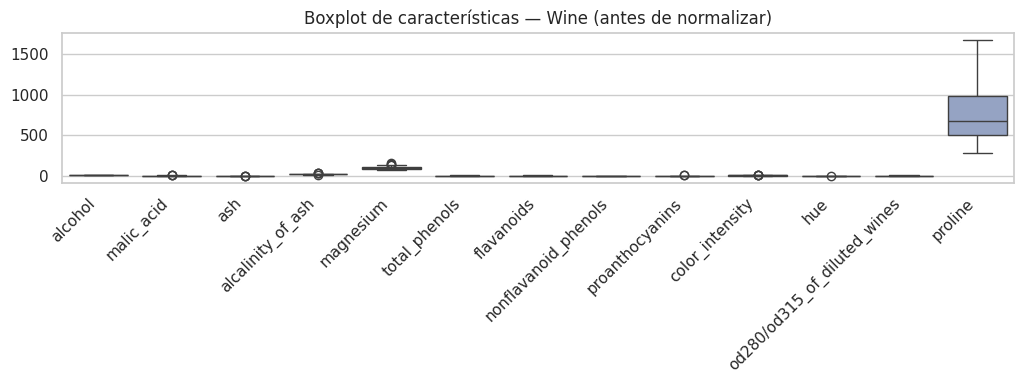

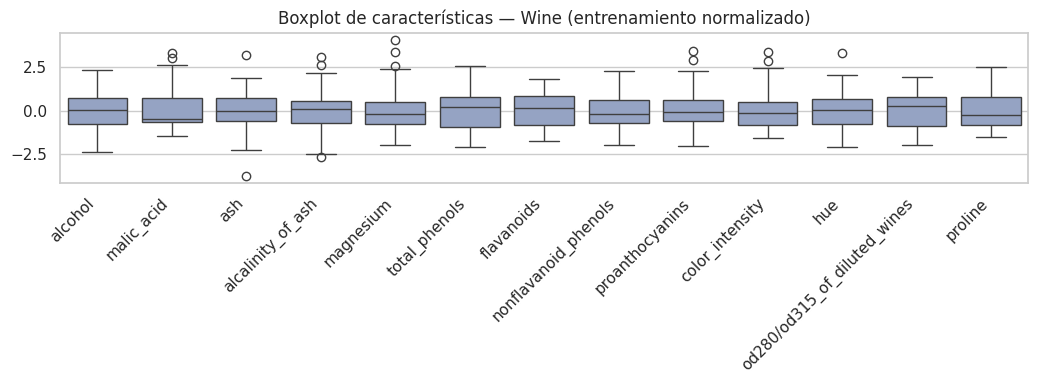

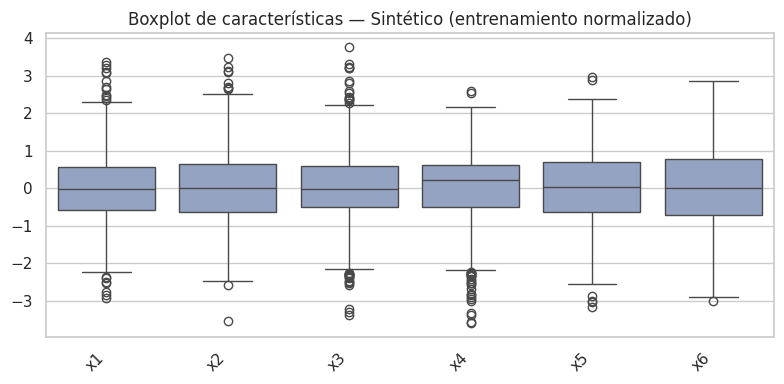

In [25]:
df_wine_n = pd.DataFrame(Xw_train_n, columns=wine.feature_names); df_wine_n["Clase"] = yw_train
df_sint_n = pd.DataFrame(Xs_train_n, columns=df_sintetico.columns[:-1]); df_sint_n["Clase"] = ys_train

graficar_boxplots(df_wine, "Wine", titulo_extra="(antes de normalizar)")
graficar_boxplots(df_wine_n, "Wine", titulo_extra="(entrenamiento normalizado)")
graficar_boxplots(df_sint_n, "Sintético", titulo_extra="(entrenamiento normalizado)")

# 5. Datasets preparados para el equipo

Se exporta cada dataset **sin normalizar** (la normalización se hace dentro de cada partición) con dos columnas
adicionales que fijan las particiones para todos los integrantes:

- `holdout`: indica si la muestra pertenece a `train` o `test` en el Hold Out 70/30.
- `fold`: número de fold (0 a 4) en el que la muestra forma parte del conjunto de prueba en K-Fold.

Estos archivos se suben al repositorio y sirven el 8 de noviembre para verificar que los tres integrantes usaron
exactamente las mismas divisiones.

In [26]:
def exportar_con_particiones(df, archivo, objetivo="Clase"):
    X, y = df.drop(columns=objetivo).values, df[objetivo].values
    indices = np.arange(len(df))
    _, idx_test = train_test_split(indices, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)
    salida = df.copy()
    salida["holdout"] = "train"
    salida.loc[idx_test, "holdout"] = "test"
    salida["fold"] = -1
    for f, (_, te) in enumerate(obtener_kfold().split(X, y)):
        salida.loc[te, "fold"] = f
    salida.to_csv(archivo, index=False)
    print(f"{archivo}: {len(salida)} filas | Hold Out -> {salida['holdout'].value_counts().to_dict()} "
          f"| muestras por fold -> {salida['fold'].value_counts().sort_index().tolist()}")
    return salida

wine_preparado = exportar_con_particiones(df_wine, "wine_preparado.csv")
sintetico_preparado = exportar_con_particiones(df_sintetico, "sintetico_preparado.csv")

wine_preparado.csv: 178 filas | Hold Out -> {'train': 124, 'test': 54} | muestras por fold -> [36, 36, 36, 35, 35]
sintetico_preparado.csv: 1000 filas | Hold Out -> {'train': 700, 'test': 300} | muestras por fold -> [200, 200, 200, 200, 200]


In [27]:
# Descargar los archivos generados (solo funciona en Google Colab)
try:
    from google.colab import files
    for archivo in ["requirements.txt", "wine_preparado.csv", "sintetico_preparado.csv"]:
        files.download(archivo)
except ImportError:
    print("Fuera de Colab: los archivos quedaron guardados en la carpeta de trabajo.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 6. Implementación K-NN desde cero

El algoritmo K-Nearest Neighbors (K-NN), o K vecinos más cercanos, es un método de clasificación supervisada basado en
la proximidad entre las observaciones.

Su funcionamiento consiste en identificar los $K$ ejemplos del conjunto de entrenamiento que se encuentran más cerca de
una muestra desconocida. Posteriormente, se asigna a dicha muestra la clase que aparece con mayor frecuencia entre sus
vecinos.

En esta práctica el algoritmo se implementa desde cero, utilizando NumPy para calcular las distancias y realizar la
selección de los vecinos, sin recurrir al clasificador `KNeighborsClassifier` de Scikit-learn.

Para determinar la proximidad entre las muestras se utiliza por defecto la distancia euclidiana:

$$d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

donde $x$ e $y$ representan dos muestras y $n$ corresponde al número de características. La implementación también
permite usar la distancia Manhattan, que servirá para probar parámetros diferentes en la optimización:

$$d(x, y) = \sum_{i=1}^{n} |x_i - y_i|$$

El algoritmo se desarrolla en tres etapas:

1. **Entrenamiento:** almacenar las muestras y sus etiquetas. K-NN es un método *perezoso* (*lazy learning*): no
   construye ningún modelo, todo el trabajo ocurre al predecir.
2. **Distancias:** calcular la distancia entre cada muestra de prueba y **todas** las muestras de entrenamiento.
3. **Votación:** seleccionar los $K$ vecinos más cercanos y asignar la clase más frecuente entre ellos.
   - Votación `uniforme`: cada vecino vale un voto (comportamiento clásico).
   - Votación `distancia`: cada vecino vota con peso $1/d$, de modo que los más cercanos pesan más.
   - **Desempate:** si dos o más clases empatan en votos, gana la del vecino más cercano entre las empatadas.

Los parámetros por defecto (`k=5`, euclidiana, votación uniforme) son los mismos que usa `KNeighborsClassifier` de
Scikit-learn, para poder comparar después "parámetros por defecto contra parámetros modificados".

## 6.1 Implementación

La clase hereda de `ClassifierMixin` y `BaseEstimator` de Scikit-learn **solo** para que sea compatible con
herramientas como `Pipeline`, `cross_val_score` y `GridSearchCV` (igual que la clase `DistanciaMinima` del
Integrante 1). Todo el algoritmo, distancias, selección de vecinos y votación, está programado con NumPy.

In [28]:
class KNNDesdeCero(ClassifierMixin, BaseEstimator):
    # Clasificador K vecinos mas cercanos implementado desde cero con NumPy

    def __init__(self, k=5, metrica="euclidiana", pesos="uniforme"):
        self.k = k
        self.metrica = metrica
        self.pesos = pesos

    def _validar_parametros(self):
        if not (isinstance(self.k, (int, np.integer)) and self.k >= 1):
            raise ValueError("k debe ser un entero mayor o igual a 1")
        if self.metrica not in ("euclidiana", "manhattan"):
            raise ValueError("metrica debe ser 'euclidiana' o 'manhattan'")
        if self.pesos not in ("uniforme", "distancia"):
            raise ValueError("pesos debe ser 'uniforme' o 'distancia'")

    # ---------- 1. Entrenamiento: solo memoriza los datos ----------
    def fit(self, X, y):
        self._validar_parametros()
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(self.y_train_)
        return self

    # ---------- 2. Matriz de distancias (n_prueba x n_entrenamiento) ----------
    def _distancias(self, X):
        if self.metrica == "euclidiana":
            # ||a - b||^2 = ||a||^2 + ||b||^2 - 2 a.b  -> calculo vectorizado, sin bucles
            d2 = (np.sum(X ** 2, axis=1)[:, np.newaxis]
                  + np.sum(self.X_train_ ** 2, axis=1)[np.newaxis, :]
                  - 2 * X @ self.X_train_.T)
            return np.sqrt(np.maximum(d2, 0))     # maximum evita negativos por redondeo
        # Manhattan: se calcula por bloques de 256 muestras para no saturar la memoria
        bloques = [np.abs(X[i:i + 256, np.newaxis, :] - self.X_train_[np.newaxis, :, :]).sum(axis=2)
                   for i in range(0, len(X), 256)]
        return np.vstack(bloques)

    # ---------- 3a. K vecinos ordenados del mas cercano al mas lejano ----------
    def kvecinos(self, X):
        X = np.asarray(X, dtype=float)
        D = self._distancias(X)
        k = min(self.k, D.shape[1])
        idx = np.argpartition(D, k - 1, axis=1)[:, :k]          # los k menores en tiempo lineal
        dist = np.take_along_axis(D, idx, axis=1)
        orden = np.argsort(dist, axis=1, kind="stable")          # solo se ordenan esos k
        return np.take_along_axis(idx, orden, axis=1), np.take_along_axis(dist, orden, axis=1)

    # ---------- 3b. Prediccion por votacion ----------
    def predict(self, X):
        idx, dist = self.kvecinos(X)
        etiquetas = self.y_train_[idx]
        w = 1.0 / (dist + 1e-12) if self.pesos == "distancia" else np.ones_like(dist)

        predicciones = np.empty(len(etiquetas), dtype=self.y_train_.dtype)
        for i in range(len(etiquetas)):
            votos = {}
            for clase, peso in zip(etiquetas[i], w[i]):
                votos[clase] = votos.get(clase, 0.0) + peso
            maximo = max(votos.values())
            empatadas = {c for c, v in votos.items() if np.isclose(v, maximo)}
            for clase in etiquetas[i]:           # vecinos ordenados por cercania
                if clase in empatadas:
                    predicciones[i] = clase
                    break
        return predicciones

print(KNNDesdeCero())

KNNDesdeCero()


## 6.2 Prueba de escritorio

Ejemplo pequeño que se puede comprobar a mano: dos grupos de puntos en el plano y tres muestras nuevas. La tercera
(3, 3) queda entre los dos grupos, pero sus 3 vecinos más cercanos pertenecen al grupo A.

Punto [1.5 1.5] -> vecinos [0, 1, 2] | distancias [0.71, 0.71, 0.71] | clase 0
Punto [6.5 6.5] -> vecinos [3, 4, 5] | distancias [0.71, 0.71, 0.71] | clase 1
Punto [3. 3.] -> vecinos [1, 2, 0] | distancias [2.24, 2.24, 2.83] | clase 0


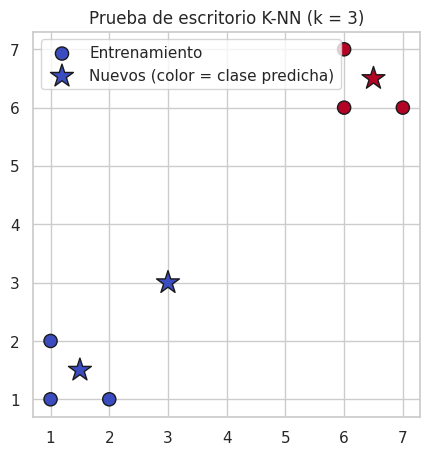

In [29]:
X_juguete = np.array([[1, 1], [1, 2], [2, 1],      # clase 0 (grupo A)
                      [6, 6], [6, 7], [7, 6]])     # clase 1 (grupo B)
y_juguete = np.array([0, 0, 0, 1, 1, 1])
puntos_nuevos = np.array([[1.5, 1.5], [6.5, 6.5], [3, 3]])

knn_juguete = KNNDesdeCero(k=3).fit(X_juguete, y_juguete)
indices, distancias = knn_juguete.kvecinos(puntos_nuevos)
predicciones = knn_juguete.predict(puntos_nuevos)

for p, i, d, c in zip(puntos_nuevos, indices, distancias, predicciones):
    print(f"Punto {p} -> vecinos {i.tolist()} | distancias {np.round(d, 2).tolist()} | clase {c}")

plt.figure(figsize=(5, 5))
plt.scatter(X_juguete[:, 0], X_juguete[:, 1], c=y_juguete, cmap="coolwarm", s=90, edgecolor="k", label="Entrenamiento")
plt.scatter(puntos_nuevos[:, 0], puntos_nuevos[:, 1], c=predicciones, cmap="coolwarm", marker="*", s=300,
            edgecolor="k", label="Nuevos (color = clase predicha)")
plt.title("Prueba de escritorio K-NN (k = 3)"); plt.legend(loc="upper left"); plt.show()

Para el punto (3, 3), la distancia a (1, 2) y a (2, 1) es $\sqrt{2^2 + 1^2} = \sqrt{5} \approx 2.24$ y a (1, 1) es
$\sqrt{2^2 + 2^2} = \sqrt{8} \approx 2.83$; las tres muestras son de la clase 0, por lo que se predice la clase 0.
Coincide con el resultado del código.

## 6.3 Validación contra Scikit-learn

Para comprobar que la implementación es correcta, se compara contra `KNeighborsClassifier` con los mismos parámetros
y la misma partición Hold Out normalizada. Si las predicciones coinciden, el K-NN propio funciona correctamente.

`KNeighborsClassifier` **no** forma parte de la solución; solo se usa como referencia para validar.

In [30]:
datasets = {"Wine": (X_wine, y_wine), "Sintético": (X_sintetico, y_sintetico)}

filas = []
for nombre, (X, y) in datasets.items():
    X_tr, X_te, y_tr, y_te = dividir_holdout(X, y)
    X_tr, X_te, _ = normalizar(X_tr, X_te)
    for k in [1, 3, 5, 7, 9]:
        for metrica, metrica_sk in [("euclidiana", "euclidean"), ("manhattan", "manhattan")]:
            pred_propio = KNNDesdeCero(k=k, metrica=metrica).fit(X_tr, y_tr).predict(X_te)
            pred_sk = KNeighborsClassifier(n_neighbors=k, metric=metrica_sk).fit(X_tr, y_tr).predict(X_te)
            filas.append({"dataset": nombre, "k": k, "métrica": metrica,
                          "predicciones_iguales_%": 100 * np.mean(pred_propio == pred_sk),
                          "exactitud_propio": accuracy_score(y_te, pred_propio),
                          "exactitud_sklearn": accuracy_score(y_te, pred_sk)})

validacion_knn = pd.DataFrame(filas)
print(f"Coincidencia promedio con Scikit-learn: {validacion_knn['predicciones_iguales_%'].mean():.2f} %")
validacion_knn.round(4)

Coincidencia promedio con Scikit-learn: 99.37 %


,dataset,k,métrica,predicciones_iguales_%,exactitud_propio,exactitud_sklearn
0,Wine,1,euclidiana,100.0000,0.9630,0.9630
1,Wine,1,manhattan,100.0000,0.9630,0.9630
2,Wine,3,euclidiana,100.0000,0.9444,0.9444
3,Wine,3,manhattan,100.0000,0.9630,0.9630
4,Wine,5,euclidiana,100.0000,0.9444,0.9444
5,Wine,5,manhattan,100.0000,0.9815,0.9815
6,Wine,7,euclidiana,100.0000,0.9444,0.9444
7,Wine,7,manhattan,100.0000,0.9815,0.9815
8,Wine,9,euclidiana,100.0000,0.9630,0.9630
9,Wine,9,manhattan,100.0000,0.9815,0.9815


**Resultado de la validación:**
- En **Wine** las predicciones coinciden al **100 %** en todas las combinaciones de $K$ y métrica.
- En el **sintético** coinciden entre 97.7 % y 100 %. Se revisaron una por una las muestras con predicción distinta
  y **todas son empates de votos** (por ejemplo, con $K = 3$, un vecino de cada clase). Scikit-learn desempata
  eligiendo la etiqueta de número menor; esta implementación elige la clase del vecino más cercano, que es un criterio
  más razonable. Con $K = 1$ no puede haber empates, y la coincidencia es del 100 % en ambos datasets.

Por lo tanto, la implementación desde cero es correcta.

## 6.4 Verificación de funcionamiento en ambos datasets

Prueba rápida con los parámetros por defecto (`k=5`, euclidiana, votación uniforme) en el Hold Out 70/30, usando las
funciones compartidas del equipo. La evaluación completa con Hold Out y K-Fold corresponde al 7 y 8 de noviembre.

Wine       exactitud 0.9444 | F1 0.9441 | entrenamiento 0.053 ms | predicción 4.919 ms
Sintético  exactitud 0.8233 | F1 0.8231 | entrenamiento 0.068 ms | predicción 83.090 ms


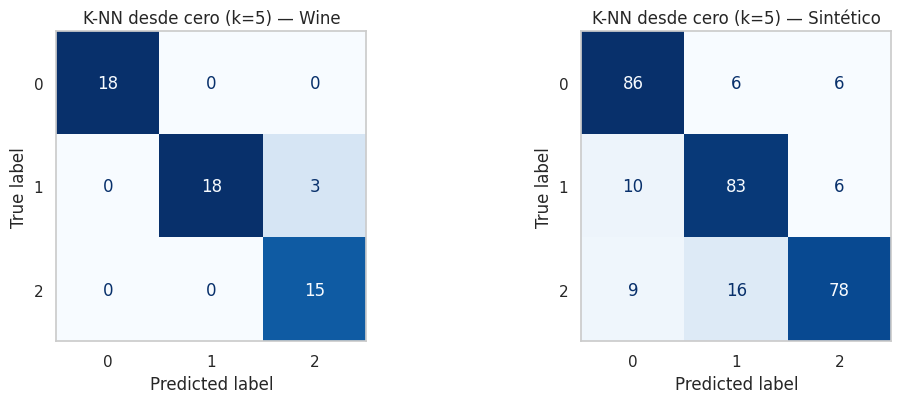

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nombre, (X, y)) in zip(axes, datasets.items()):
    resultado, (y_real, y_pred) = evaluar_holdout(KNNDesdeCero(k=5), X, y)
    print(f"{nombre:<10} exactitud {resultado['exactitud']:.4f} | F1 {resultado['f1']:.4f} | "
          f"entrenamiento {resultado['t_fit_ms']:.3f} ms | predicción {resultado['t_pred_ms']:.3f} ms")
    ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)
    ax.set_title(f"K-NN desde cero (k=5) — {nombre}")
plt.tight_layout(); plt.show()

## 6.5 Efecto de la normalización en K-NN

Misma partición y mismo $K$, con y sin estandarización, evaluado con K-Fold (5 folds). Este resultado comprueba la
decisión tomada en la sección 4.

In [32]:
filas = []
for nombre, (X, y) in datasets.items():
    sin_norm, _ = evaluar_kfold(KNNDesdeCero(k=5), X, y, escalar=False)
    con_norm, _ = evaluar_kfold(KNNDesdeCero(k=5), X, y, escalar=True)
    filas.append({"dataset": nombre,
                  "exactitud_sin_normalizar": sin_norm["exactitud"],
                  "exactitud_normalizado": con_norm["exactitud"],
                  "diferencia_puntos": 100 * (con_norm["exactitud"] - sin_norm["exactitud"])})
pd.DataFrame(filas).round(4)

,dataset,exactitud_sin_normalizar,exactitud_normalizado,diferencia_puntos
0,Wine,0.6743,0.9717,29.746
1,Sintético,0.8550,0.8560,0.100


**Resultado:** en **Wine** normalizar sube la exactitud de K-NN de 67.4 % a 97.2 % (casi 30 puntos), porque sin
normalizar `proline` (valores de cientos) y `magnesium` dominan la distancia y las demás características casi no
cuentan. En el **sintético** la diferencia es de solo 0.1 puntos, porque, como se vio en el análisis exploratorio, sus
características ya tienen escalas parecidas. Esto confirma que la normalización es indispensable para K-NN cuando las
escalas son distintas.

# 7. Implementación Naïve Bayes

Naïve Bayes es un clasificador probabilístico basado en el **teorema de Bayes**. Para una muestra
$x = (x_1, \dots, x_n)$ calcula la probabilidad de que pertenezca a cada clase $c$:

$$P(c \mid x) = \frac{P(c)\, P(x \mid c)}{P(x)}$$

- $P(c)$: probabilidad *a priori* de la clase (proporción de muestras de esa clase en el entrenamiento).
- $P(x \mid c)$: verosimilitud, qué tan probable es observar $x$ si la muestra es de la clase $c$.
- $P(x)$: es igual para todas las clases, por lo que no afecta la decisión.

La suposición "ingenua" (*naïve*) es que las características son **independientes entre sí dada la clase**, lo que
permite escribir la verosimilitud como un producto:

$$P(x \mid c) = \prod_{j=1}^{n} P(x_j \mid c)$$

Como las características de ambos datasets son numéricas continuas, se usa **Naïve Bayes Gaussiano**: cada
característica se modela con una distribución normal con media $\mu_{cj}$ y varianza $\sigma^2_{cj}$ calculadas por
clase:

$$P(x_j \mid c) = \frac{1}{\sqrt{2\pi\sigma^2_{cj}}} \exp\left(-\frac{(x_j - \mu_{cj})^2}{2\sigma^2_{cj}}\right)$$

La clase predicha es la de mayor probabilidad. Para evitar que el producto de muchas probabilidades pequeñas dé cero
por redondeo, se trabaja con logaritmos:

$$\hat{c} = \arg\max_c \left[ \log P(c) + \sum_{j=1}^{n} \log P(x_j \mid c) \right]$$

Se implementa con `GaussianNB` de Scikit-learn, con sus parámetros por defecto: `priors=None` (las probabilidades
a priori se estiman de los datos) y `var_smoothing=1e-9` (se suma una pequeña cantidad a las varianzas para evitar
divisiones entre cero).

## 7.1 Entrenamiento y parámetros aprendidos

Se entrena con el Hold Out 70/30 de Wine para ver qué aprende el modelo. A diferencia de K-NN, Naïve Bayes sí
construye un modelo: solo necesita guardar una probabilidad a priori por clase y una media y una varianza por cada
combinación de clase y característica.

In [33]:
nb_wine = GaussianNB()
nb_wine.fit(Xw_train, yw_train)          # datos sin normalizar (ver seccion 7.3)

print("Probabilidades a priori P(c):", np.round(nb_wine.class_prior_, 4))
print("Muestras por clase en entrenamiento:", nb_wine.class_count_.astype(int))
print(f"Parámetros aprendidos: {nb_wine.theta_.size} medias + {nb_wine.var_.size} varianzas "
      f"+ {nb_wine.class_prior_.size} probabilidades a priori")

pd.DataFrame(nb_wine.theta_.T, index=wine.feature_names,
             columns=[f"media clase {c}" for c in nb_wine.classes_]).round(3)

Probabilidades a priori P(c): [0.3306 0.4032 0.2661]
Muestras por clase en entrenamiento: [41 50 33]
Parámetros aprendidos: 39 medias + 39 varianzas + 3 probabilidades a priori


,media clase 0,media clase 1,media clase 2
alcohol,13.730,12.242,13.075
malic_acid,1.947,1.963,3.201
ash,2.450,2.233,2.454
alcalinity_of_ash,17.102,20.524,21.561
magnesium,106.634,95.140,99.273
total_phenols,2.829,2.254,1.688
flavanoids,2.940,2.047,0.788
nonflavanoid_phenols,0.302,0.351,0.446
proanthocyanins,1.851,1.712,1.139
color_intensity,5.568,2.961,7.363


## 7.2 Comprobación manual de una predicción

Para entender lo que hace `GaussianNB` internamente, se calcula a mano la probabilidad de cada clase para la muestra
de prueba en la que el modelo está menos seguro, usando las fórmulas anteriores y los parámetros aprendidos, y se compara con `predict_proba`.

In [34]:
# Se elige la muestra de prueba en la que el modelo esta menos seguro, para que el ejemplo sea interesante
i = np.argmin(nb_wine.predict_proba(Xw_test).max(axis=1))
x = Xw_test[i]

log_prior = np.log(nb_wine.class_prior_)
log_verosimilitud = -0.5 * np.sum(np.log(2 * np.pi * nb_wine.var_)
                                  + (x - nb_wine.theta_) ** 2 / nb_wine.var_, axis=1)
log_posterior = log_prior + log_verosimilitud

# Normalizacion para que las probabilidades sumen 1 (equivale a dividir entre P(x))
prob_manual = np.exp(log_posterior - log_posterior.max())
prob_manual /= prob_manual.sum()

print("log P(c) + Σ log P(x_j|c):  ", np.round(log_posterior, 3))
print("Probabilidad manual:         ", np.round(prob_manual, 4))
print("Probabilidad GaussianNB:     ", np.round(nb_wine.predict_proba([x])[0], 4))
print(f"Clase predicha manual: {np.argmax(prob_manual)} | GaussianNB: {nb_wine.predict([x])[0]} "
      f"| Clase real: {yw_test[i]}")

log P(c) + Σ log P(x_j|c):   [-26.886 -26.763 -88.464]
Probabilidad manual:          [0.4692 0.5308 0.    ]
Probabilidad GaussianNB:      [0.4692 0.5308 0.    ]
Clase predicha manual: 1 | GaussianNB: 1 | Clase real: 1


## 7.3 Verificación de funcionamiento en ambos datasets

Prueba rápida con los parámetros por defecto en el Hold Out 70/30, con las funciones compartidas del equipo. También
se compara con y sin normalización: como Naïve Bayes modela cada característica por separado con su propia media y
varianza, cambiar la escala de una característica no cambia sus decisiones.

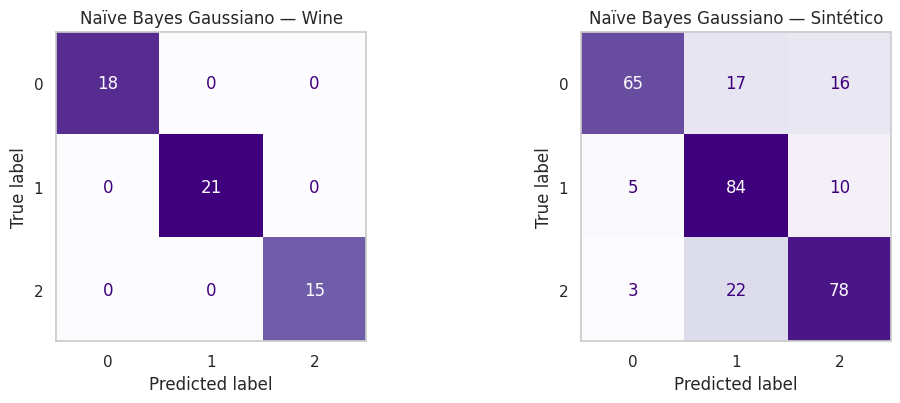

,dataset,exactitud_sin_normalizar,exactitud_normalizado,f1,t_fit_ms,t_pred_ms
0,Wine,1.0000,1.0000,1.0000,3.6944,0.4265
1,Sintético,0.7567,0.7567,0.7569,5.7596,0.5718


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
filas = []
for ax, (nombre, (X, y)) in zip(axes, datasets.items()):
    res_sin, (y_real, y_pred) = evaluar_holdout(GaussianNB(), X, y, escalar=False)
    res_con, _ = evaluar_holdout(GaussianNB(), X, y, escalar=True)
    filas.append({"dataset": nombre, "exactitud_sin_normalizar": res_sin["exactitud"],
                  "exactitud_normalizado": res_con["exactitud"], "f1": res_sin["f1"],
                  "t_fit_ms": res_sin["t_fit_ms"], "t_pred_ms": res_sin["t_pred_ms"]})
    ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred)).plot(ax=ax, cmap="Purples", colorbar=False)
    ax.grid(False)
    ax.set_title(f"Naïve Bayes Gaussiano — {nombre}")
plt.tight_layout(); plt.show()
pd.DataFrame(filas).round(4)

**Resultado:**
- La exactitud es **idéntica con y sin normalización** en ambos datasets, como se esperaba. Por eso Naïve Bayes se
  evalúa sin normalizar.
- En **Wine** Naïve Bayes clasifica correctamente las 54 muestras de prueba (100 %). Las clases de Wine tienen
  distribuciones aproximadamente normales y bien separadas en varias características (sección 3.2), justo lo que
  supone el modelo.
- En el **sintético** obtiene 75.7 %, menos que K-NN (82.3 %). Este dataset tiene características redundantes y muy
  correlacionadas y ruido correlacionado entre `x1` y `x2`, lo que rompe la suposición de independencia (ver 7.4).

## 7.4 Relación con el análisis exploratorio

En la sección 3 se encontraron características fuertemente correlacionadas en ambos datasets (por ejemplo
`total_phenols`–`flavanoids` en Wine con r ≈ 0.86 y `x1`–`x4` en el sintético con r ≈ 0.83). Esto **viola la
suposición de independencia** de Naïve Bayes: al tratar dos características correlacionadas como independientes, el
modelo cuenta dos veces casi la misma información.

Aun así, Naïve Bayes suele clasificar bien, porque para acertar no necesita estimar las probabilidades con precisión:
basta con que la clase correcta quede con la probabilidad más alta. Este punto se retomará en la comparación de
resultados y en las conclusiones.

## 7.5 Comparación rápida K-NN y Naïve Bayes

Resumen de la verificación de ambos modelos con sus parámetros por defecto en el Hold Out 70/30. Es solo un primer
vistazo; la comparación formal de los seis clasificadores se hará con los resultados de todo el equipo.

In [36]:
filas = []
for nombre, (X, y) in datasets.items():
    for modelo_nombre, modelo, escalar in [("K-NN desde cero (k=5)", KNNDesdeCero(k=5), True),
                                          ("Naïve Bayes Gaussiano", GaussianNB(), False)]:
        res, _ = evaluar_holdout(modelo, X, y, escalar=escalar)
        filas.append({"dataset": nombre, "modelo": modelo_nombre, **res})

resumen_dia_6 = pd.DataFrame(filas)
resumen_dia_6.round(4)

,dataset,modelo,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
0,Wine,K-NN desde cero (k=5),0.9444,0.9444,0.9524,0.9441,0.0518,9.4232
1,Wine,Naïve Bayes Gaussiano,1.0000,1.0000,1.0000,1.0000,4.3629,0.4463
2,Sintético,K-NN desde cero (k=5),0.8233,0.8254,0.8244,0.8231,0.0684,108.4305
3,Sintético,Naïve Bayes Gaussiano,0.7567,0.7744,0.7563,0.7569,5.8425,0.6520


Las columnas `t_fit_ms` y `t_pred_ms` muestran la diferencia de comportamiento entre los dos modelos: K-NN casi no
tarda en entrenar (solo guarda los datos) y concentra su tiempo en la predicción, porque compara cada muestra de
prueba contra todo el entrenamiento. Naïve Bayes, en cambio, invierte un poco de tiempo en calcular medias y varianzas
al entrenar, y luego predice muy rápido. Este análisis se formalizará en la sección de complejidad temporal.

# 8. Pruebas de K-NN y Naïve Bayes en ambos datasets (7 de noviembre)

En esta sección se obtienen las **primeras métricas completas** de los dos clasificadores del Integrante 3, con los dos
métodos de validación que pide la práctica y en los dos datasets: 2 modelos × 2 datasets × 2 validaciones = **8
experimentos**.

## 8.1 Configuración de los experimentos

| Modelo | Parámetros | Normalización |
|---|---|---|
| K-NN desde cero | Por defecto: `k=5`, distancia euclidiana, votación uniforme | Sí (z-score, ajustado solo con entrenamiento) |
| Naïve Bayes Gaussiano | Por defecto: `priors=None`, `var_smoothing=1e-9` | No (no la necesita, ver sección 7.3) |

- **Hold Out:** 70 % entrenamiento y 30 % prueba, estratificado, `random_state=42`.
- **K-Fold:** 5 folds estratificados con `shuffle=True` y `random_state=42`. Se reporta el **promedio** y la
  **desviación estándar** de los 5 folds. La desviación se calcula igual que `cross_val_score(...).std()`, que es
  lo que usa el Integrante 1, para que las tablas del equipo sean comparables.
- **Métricas:** exactitud, precisión, recall y F1 (promedio *macro*), y tiempos de entrenamiento y predicción en
  milisegundos.

Las particiones son exactamente las mismas que usa el Integrante 1 y las mismas que quedaron guardadas en
`wine_preparado.csv` y `sintetico_preparado.csv`. Todos los experimentos usan las funciones compartidas de la sección
1.4.

In [37]:
# Modelos del Integrante 3: (nombre, modelo, normalizar)
MODELOS_INT3 = [
    ("K-NN (k=5)", KNNDesdeCero(k=5), True),
    ("Naïve Bayes", GaussianNB(), False),
]
# datasets ya definido en la seccion 6.3: {"Wine": (X_wine, y_wine), "Sintético": (X_sintetico, y_sintetico)}

METRICAS = ["exactitud", "precision", "recall", "f1"]

def formato_tabla(df, columnas_pct, columnas_ms=()):
    # Muestra las metricas en porcentaje y los tiempos en ms
    formato = {c: "{:.2f} %" for c in columnas_pct}
    formato.update({c: "{:.3f}" for c in columnas_ms})
    return df.style.format(formato).hide(axis="index")

print("Experimentos configurados:", len(MODELOS_INT3) * len(datasets) * 2)

Experimentos configurados: 8


## 8.2 Evaluación Hold Out 70/30

Cada modelo se entrena con el 70 % de los datos y se evalúa una sola vez con el 30 % restante.

In [38]:
filas_ho, predicciones_ho = [], {}
for nombre_ds, (X, y) in datasets.items():
    for nombre_modelo, modelo, escalar in MODELOS_INT3:
        res, (y_real, y_pred) = evaluar_holdout(modelo, X, y, escalar=escalar)
        predicciones_ho[(nombre_ds, nombre_modelo)] = (y_real, y_pred)
        filas_ho.append({"dataset": nombre_ds, "modelo": nombre_modelo,
                         **{m: 100 * res[m] for m in METRICAS},
                         "t_fit_ms": res["t_fit_ms"], "t_pred_ms": res["t_pred_ms"]})

resultados_ho = pd.DataFrame(filas_ho)
formato_tabla(resultados_ho, METRICAS, ["t_fit_ms", "t_pred_ms"])

dataset,modelo,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
Wine,K-NN (k=5),94.44 %,94.44 %,95.24 %,94.41 %,0.052,25.084
Wine,Naïve Bayes,100.00 %,100.00 %,100.00 %,100.00 %,1.312,0.414
Sintético,K-NN (k=5),82.33 %,82.54 %,82.44 %,82.31 %,0.065,86.097
Sintético,Naïve Bayes,75.67 %,77.44 %,75.63 %,75.69 %,3.966,0.532


### Matrices de confusión (Hold Out)

Filas = clase real, columnas = clase predicha. La diagonal son los aciertos; fuera de la diagonal están las
confusiones.

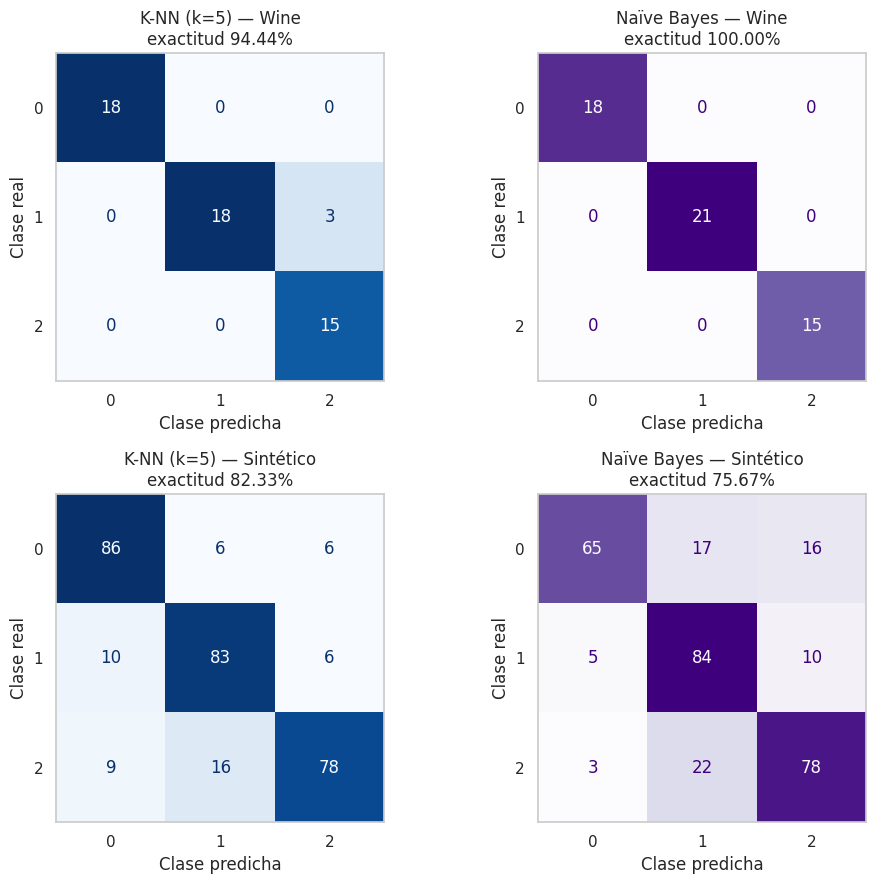

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for fila, nombre_ds in enumerate(datasets):
    for col, (nombre_modelo, _, _) in enumerate(MODELOS_INT3):
        y_real, y_pred = predicciones_ho[(nombre_ds, nombre_modelo)]
        ax = axes[fila, col]
        ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred)).plot(
            ax=ax, cmap="Blues" if col == 0 else "Purples", colorbar=False)
        ax.grid(False)
        ax.set_title(f"{nombre_modelo} — {nombre_ds}\nexactitud {accuracy_score(y_real, y_pred):.2%}")
        ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout(); plt.show()

### Desempeño por clase (Hold Out)

El reporte por clase muestra si algún modelo tiene problemas con una clase en particular, algo que la exactitud
global puede ocultar.

In [40]:
for (nombre_ds, nombre_modelo), (y_real, y_pred) in predicciones_ho.items():
    print(f"========== {nombre_modelo} — {nombre_ds} ==========")
    print(classification_report(y_real, y_pred, digits=3, zero_division=0))

========== K-NN (k=5) — Wine ==========
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        18
           1      1.000     0.857     0.923        21
           2      0.833     1.000     0.909        15

    accuracy                          0.944        54
   macro avg      0.944     0.952     0.944        54
weighted avg      0.954     0.944     0.945        54

========== Naïve Bayes — Wine ==========
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        18
           1      1.000     1.000     1.000        21
           2      1.000     1.000     1.000        15

    accuracy                          1.000        54
   macro avg      1.000     1.000     1.000        54
weighted avg      1.000     1.000     1.000        54

========== K-NN (k=5) — Sintético ==========
              precision    recall  f1-score   support

           0      0.819     0.878     0.847        98
   

## 8.3 Evaluación K-Fold (k = 5)

Cada modelo se entrena y evalúa 5 veces; en cada ronda un fold distinto funciona como conjunto de prueba. En K-NN la
normalización se vuelve a ajustar en cada ronda, solo con los 4 folds de entrenamiento.

In [41]:
filas_kf, detalle_kf = [], []
for nombre_ds, (X, y) in datasets.items():
    for nombre_modelo, modelo, escalar in MODELOS_INT3:
        resumen, por_fold = evaluar_kfold(modelo, X, y, escalar=escalar)
        fila = {"dataset": nombre_ds, "modelo": nombre_modelo}
        for m in METRICAS:
            fila[m] = 100 * por_fold[m].mean()
            fila[f"{m}_std"] = 100 * por_fold[m].std(ddof=0)
        fila["t_fit_ms"] = por_fold["t_fit_ms"].mean()
        fila["t_pred_ms"] = por_fold["t_pred_ms"].mean()
        filas_kf.append(fila)
        por_fold = por_fold.assign(dataset=nombre_ds, modelo=nombre_modelo, fold=range(1, N_FOLDS + 1))
        detalle_kf.append(por_fold)

resultados_kf = pd.DataFrame(filas_kf)
detalle_kf = pd.concat(detalle_kf, ignore_index=True)

# Tabla con formato "promedio ± desviación"
tabla_kf = resultados_kf[["dataset", "modelo"]].copy()
for m in METRICAS:
    tabla_kf[m] = [f"{a:.2f} ± {b:.2f} %" for a, b in zip(resultados_kf[m], resultados_kf[f"{m}_std"])]
tabla_kf["t_fit_ms"] = resultados_kf["t_fit_ms"].round(3)
tabla_kf["t_pred_ms"] = resultados_kf["t_pred_ms"].round(3)
tabla_kf

,dataset,modelo,exactitud,precision,recall,f1,t_fit_ms,t_pred_ms
0,Wine,K-NN (k=5),97.17 ± 1.81 %,97.03 ± 1.88 %,97.65 ± 1.51 %,97.21 ± 1.79 %,0.042,3.931
1,Wine,Naïve Bayes,97.19 ± 2.52 %,97.28 ± 2.37 %,97.46 ± 2.31 %,97.32 ± 2.37 %,2.131,1.242
2,Sintético,K-NN (k=5),85.60 ± 1.88 %,85.74 ± 1.79 %,85.65 ± 1.83 %,85.57 ± 1.87 %,0.072,32.301
3,Sintético,Naïve Bayes,75.30 ± 3.98 %,76.31 ± 3.86 %,75.25 ± 3.95 %,75.35 ± 3.95 %,2.598,0.455


### Exactitud en cada fold

La desviación estándar resume qué tanto cambia el resultado de un fold a otro. Una desviación pequeña indica un
modelo **estable**: su desempeño no depende mucho de qué muestras le tocaron como prueba.

fold 1  fold 2  fold 3  fold 4  fold 5
dataset   modelo                                             
Sintético K-NN (k=5)    87.00   85.00   88.50   83.50   84.00
          Naïve Bayes   82.00   71.50   75.50   76.50   71.00
Wine      K-NN (k=5)    97.22   97.22  100.00   94.29   97.14
          Naïve Bayes   94.44  100.00   97.22   94.29  100.00

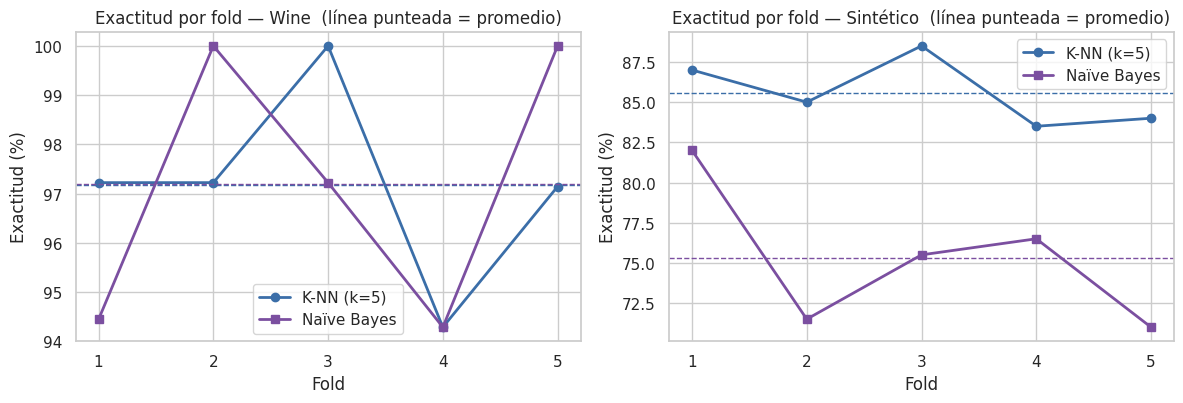

In [42]:
pivote = (detalle_kf.assign(exactitud=100 * detalle_kf["exactitud"])
          .pivot_table(index=["dataset", "modelo"], columns="fold", values="exactitud"))
pivote.columns = [f"fold {c}" for c in pivote.columns]
display(pivote.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, nombre_ds in zip(axes, datasets):
    datos = detalle_kf[detalle_kf["dataset"] == nombre_ds]
    for (nombre_modelo, _, _), color, marca in zip(MODELOS_INT3, ["#3B6EA8", "#7B4FA0"], ["o", "s"]):
        d = datos[datos["modelo"] == nombre_modelo]
        ax.plot(d["fold"], 100 * d["exactitud"], marker=marca, color=color, lw=2, label=nombre_modelo)
        ax.axhline(100 * d["exactitud"].mean(), color=color, ls="--", lw=1)
    ax.set_title(f"Exactitud por fold — {nombre_ds}  (línea punteada = promedio)")
    ax.set_xlabel("Fold"); ax.set_ylabel("Exactitud (%)"); ax.set_xticks(range(1, N_FOLDS + 1))
    ax.legend()
plt.tight_layout(); plt.show()

## 8.4 Hold Out contra K-Fold

Se comparan las dos validaciones para cada modelo y dataset. Con K-Fold se muestra la desviación estándar como barra
de error.

,dataset,modelo,exactitud_holdout,f1_holdout,exactitud_kfold,exactitud_std,f1_kfold,diferencia_exactitud
0,Wine,K-NN (k=5),94.44,94.41,97.17,1.81,97.21,2.73
1,Wine,Naïve Bayes,100.00,100.00,97.19,2.52,97.32,-2.81
2,Sintético,K-NN (k=5),82.33,82.31,85.60,1.88,85.57,3.27
3,Sintético,Naïve Bayes,75.67,75.69,75.30,3.98,75.35,-0.37


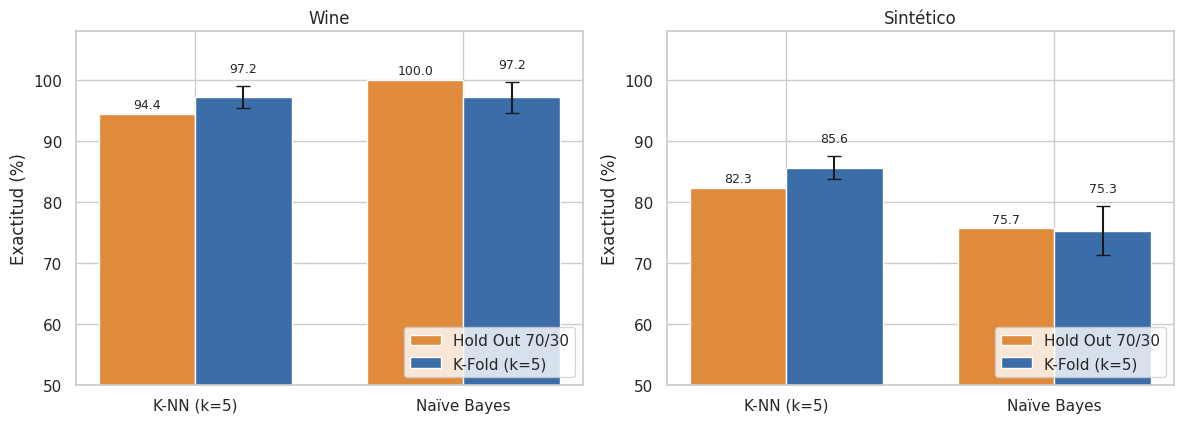

In [43]:
comparacion = resultados_ho[["dataset", "modelo", "exactitud", "f1"]].merge(
    resultados_kf[["dataset", "modelo", "exactitud", "exactitud_std", "f1"]],
    on=["dataset", "modelo"], suffixes=("_holdout", "_kfold"))
comparacion["diferencia_exactitud"] = comparacion["exactitud_kfold"] - comparacion["exactitud_holdout"]
display(comparacion.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ancho = 0.36
for ax, nombre_ds in zip(axes, datasets):
    c = comparacion[comparacion["dataset"] == nombre_ds].reset_index(drop=True)
    x = np.arange(len(c))
    b1 = ax.bar(x - ancho / 2, c["exactitud_holdout"], ancho, label="Hold Out 70/30", color="#E08A3C")
    b2 = ax.bar(x + ancho / 2, c["exactitud_kfold"], ancho, yerr=c["exactitud_std"], capsize=5,
                label="K-Fold (k=5)", color="#3B6EA8")
    ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=9)
    ax.bar_label(b2, fmt="%.1f", padding=8, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(c["modelo"])
    ax.set_ylim(50, 108); ax.set_ylabel("Exactitud (%)"); ax.set_title(nombre_ds)
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8.5 Tiempos de ejecución

Promedio de los 5 folds, en milisegundos. Los tiempos dependen de la computadora y pueden variar ligeramente entre
ejecuciones, pero la diferencia entre modelos se mantiene.

,dataset,modelo,t_fit_ms,t_pred_ms,t_total_ms
0,Wine,K-NN (k=5),0.042,3.931,3.973
1,Wine,Naïve Bayes,2.131,1.242,3.373
2,Sintético,K-NN (k=5),0.072,32.301,32.373
3,Sintético,Naïve Bayes,2.598,0.455,3.053


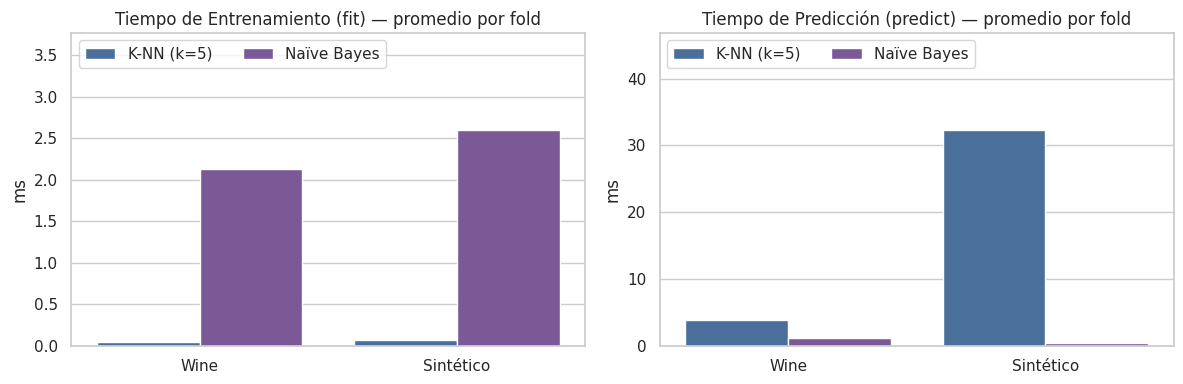

In [44]:
tiempos = resultados_kf[["dataset", "modelo", "t_fit_ms", "t_pred_ms"]].copy()
tiempos["t_total_ms"] = tiempos["t_fit_ms"] + tiempos["t_pred_ms"]
display(tiempos.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, columna, titulo in [(axes[0], "t_fit_ms", "Entrenamiento (fit)"), (axes[1], "t_pred_ms", "Predicción (predict)")]:
    sns.barplot(data=tiempos, x="dataset", y=columna, hue="modelo", palette=["#3B6EA8", "#7B4FA0"], ax=ax)
    ax.set_title(f"Tiempo de {titulo} — promedio por fold"); ax.set_ylabel("ms"); ax.set_xlabel("")
    ax.set_ylim(0, tiempos[columna].max() * 1.45)
    ax.legend(title="", loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## 8.6 Observaciones

### Wine
- **Los dos modelos empatan en K-Fold:** K-NN 97.17 % y Naïve Bayes 97.19 % de exactitud. En el Hold Out parece que
  Naïve Bayes es mucho mejor (100 % contra 94.4 %), pero K-Fold muestra que esa diferencia se debe a la partición:
  con solo 54 muestras de prueba, 3 errores bajan la exactitud 5.6 puntos.
- **Errores de K-NN en el Hold Out:** los 3 errores son vinos de la clase 1 clasificados como clase 2 (recall de la
  clase 1 de 85.7 %). La clase 0 la clasifican perfectamente los dos modelos.
- **Los dos son estables:** la exactitud por fold va de 94.3 % a 100 %, con desviación estándar de 1.81 (K-NN) y
  2.52 (Naïve Bayes).
- Ambos funcionan bien porque Wine tiene clases bien separadas (sección 3.2) y, una vez normalizado, las distancias
  reflejan bien el parecido entre vinos.

### Sintético
- **K-NN es claramente mejor:** 85.60 % contra 75.30 % en K-Fold (10.3 puntos de diferencia) y 82.3 % contra 75.7 %
  en Hold Out. Precisión, recall y F1 siguen el mismo patrón.
- **Dónde falla Naïve Bayes:** sobre todo en la clase 0, con recall de solo 66.3 %: de 98 muestras de esa clase, 17
  las confunde con la clase 1 y 16 con la clase 2. También confunde 22 muestras de la clase 2 con la clase 1.
- **Por qué:** Naïve Bayes supone que las características son independientes y que cada una sigue una campana por
  clase. El sintético tiene características redundantes y muy correlacionadas (x1–x4 con r ≈ 0.83, x2–x6 con
  r ≈ −0.76) más el ruido correlacionado entre x1 y x2, así que esa suposición no se cumple. K-NN no supone nada sobre
  la forma de los datos: solo mira qué muestras están cerca, por lo que no le afectan las correlaciones.
- **Naïve Bayes es el menos estable:** su exactitud por fold va de 71.0 % a 82.0 % (desviación de 3.98), el doble de
  variación que K-NN (1.88).
- Ningún modelo se acerca al 100 % porque el 5 % de etiquetas alteradas y el traslape entre clases ponen un límite a
  lo que se puede acertar.

### Hold Out contra K-Fold
- Las dos validaciones difieren hasta en 3.3 puntos. En K-NN el Hold Out salió más bajo que el K-Fold en ambos
  datasets; en Naïve Bayes con Wine salió más alto.
- El Hold Out depende de una sola división, mientras que K-Fold promedia 5 y usa todas las muestras como prueba una
  vez. Por eso **K-Fold es la estimación más confiable**, sobre todo en Wine, que tiene pocas muestras. El Hold Out
  sirve como complemento y para revisar las matrices de confusión.

### Tiempos
- **K-NN:** entrenar es casi instantáneo (alrededor de 0.02 ms, porque solo guarda los datos), pero predecir es lo
  más lento y crece con el tamaño del dataset: de aproximadamente 0.8 ms en Wine a 5 ms en el sintético, que tiene
  más muestras de entrenamiento (800 contra unas 142 por fold) y más muestras de prueba (200 contra unas 36).
- **Naïve Bayes:** tarda un poco más en entrenar (alrededor de 0.7 ms, para calcular medias y varianzas), pero
  predice en unos 0.2 ms casi sin importar el tamaño del dataset.
- Es decir, K-NN es barato al entrenar y caro al predecir, y Naïve Bayes al revés. Esto se analizará formalmente en
  la sección de complejidad temporal.

### Conclusión preliminar
Con parámetros por defecto, **K-NN es el más robusto de los dos**: empata en Wine y gana por amplio margen en el
sintético. Naïve Bayes es competitivo cuando sus suposiciones se cumplen (Wine) y es mucho más rápido para predecir.
Falta comprobar si K-NN mejora con otros parámetros (9 de noviembre).

## 8.7 Resultados para integrar con el equipo

Se guardan los resultados en `resultados_integrante3.csv` con un formato que los demás integrantes pueden repetir
(una fila por dataset, modelo y validación). El 8 de noviembre se juntarán los tres archivos para formar la tabla
comparativa de los seis clasificadores.

In [45]:
columnas = ["dataset", "modelo", "validacion"] + METRICAS + ["exactitud_std", "t_fit_ms", "t_pred_ms"]
resultados_int3 = pd.concat([
    resultados_ho.assign(validacion="Hold Out 70/30", exactitud_std=np.nan),
    resultados_kf.assign(validacion=f"K-Fold (k={N_FOLDS})"),
], ignore_index=True)[columnas]

resultados_int3.round(4).to_csv("resultados_integrante3.csv", index=False)
print("Guardado: resultados_integrante3.csv")
resultados_int3.round(2)

Guardado: resultados_integrante3.csv


,dataset,modelo,validacion,exactitud,precision,recall,f1,exactitud_std,t_fit_ms,t_pred_ms
0,Wine,K-NN (k=5),Hold Out 70/30,94.44,94.44,95.24,94.41,NaN,0.05,25.08
1,Wine,Naïve Bayes,Hold Out 70/30,100.00,100.00,100.00,100.00,NaN,1.31,0.41
2,Sintético,K-NN (k=5),Hold Out 70/30,82.33,82.54,82.44,82.31,NaN,0.06,86.10
3,Sintético,Naïve Bayes,Hold Out 70/30,75.67,77.44,75.63,75.69,NaN,3.97,0.53
4,Wine,K-NN (k=5),K-Fold (k=5),97.17,97.03,97.65,97.21,1.81,0.04,3.93
5,Wine,Naïve Bayes,K-Fold (k=5),97.19,97.28,97.46,97.32,2.52,2.13,1.24
6,Sintético,K-NN (k=5),K-Fold (k=5),85.60,85.74,85.65,85.57,1.88,0.07,32.30
7,Sintético,Naïve Bayes,K-Fold (k=5),75.30,76.31,75.25,75.35,3.98,2.60,0.45


In [46]:
# Descargar el archivo de resultados (solo funciona en Google Colab)
try:
    from google.colab import files
    files.download("resultados_integrante3.csv")
except ImportError:
    print("Fuera de Colab: el archivo quedó guardado en la carpeta de trabajo.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 9. Integración de resultados y verificación de divisiones (8 de noviembre)

Esta sección corresponde a la tarea del Integrante 3 del 8 de noviembre: **integrar los resultados de validación de
los tres integrantes y verificar que todos utilicen las mismas divisiones**. Sin esa verificación, la comparación de los
seis clasificadores no sería justa: un modelo podría verse mejor solo porque le tocó un conjunto de prueba más fácil.

## 9.1 Cómo divide los datos cada integrante

| Integrante | Modelos | Hold Out | K-Fold |
|---|---|---|---|
| 1 | Distancia Mínima, MLP | `train_test_split(test_size=0.30, stratify=y, random_state=42)` | `StratifiedKFold(5, shuffle=True, random_state=42)` con `cross_val_score` |
| 2 | 1-NN, SVM | Columna `holdout` de los CSV del repositorio | `StratifiedKFold(5, shuffle=True, random_state=42)` sobre los CSV del repositorio |
| 3 | K-NN, Naïve Bayes | Funciones compartidas (sección 1.4), mismos parámetros que el Integrante 1 | Funciones compartidas, mismos parámetros que el Integrante 1 |

Los tres caminos deberían producir **exactamente** las mismas particiones. A continuación se comprueba.

## 9.2 Verificación de las divisiones

Se cargan los CSV **desde el repositorio** (los mismos archivos que usa el Integrante 2) y se comparan tres cosas:

1. Que los datos del CSV sean idénticos a los que se generan en este notebook (y en el del Integrante 1).
2. Que la columna `holdout` coincida con la partición de `train_test_split` que usan los Integrantes 1 y 3.
3. Que la columna `fold` coincida con los folds de `StratifiedKFold` que usan los Integrantes 1 y 3.

In [47]:
URL_REPO = "https://raw.githubusercontent.com/paolamrk/Practica3_MachineLearning/refs/heads/main/"

def cargar_csv_equipo(nombre):
    # Intenta leer el CSV del repositorio; si no hay internet, usa el archivo local de la seccion 5
    try:
        return pd.read_csv(URL_REPO + nombre), "repositorio"
    except Exception:
        return pd.read_csv(nombre), "archivo local"

verificacion = []
for nombre_ds, (X, y), archivo in [("Wine", datasets["Wine"], "wine_preparado.csv"),
                                    ("Sintético", datasets["Sintético"], "sintetico_preparado.csv")]:
    df_csv, origen = cargar_csv_equipo(archivo)
    X_csv = df_csv.drop(columns=["Clase", "holdout", "fold"]).values
    y_csv = df_csv["Clase"].values

    # 1. Mismos datos
    mismos_datos = X_csv.shape == X.shape and np.allclose(X_csv, X, atol=1e-9) and np.array_equal(y_csv, y)

    # 2. Mismo Hold Out (Integrantes 1 y 3 usan train_test_split; Integrante 2 usa la columna holdout)
    _, idx_test = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)
    mismo_holdout = set(idx_test) == set(np.where(df_csv["holdout"] == "test")[0])

    # 3. Mismos folds
    mismos_folds = all(set(te) == set(np.where(df_csv["fold"] == f)[0])
                       for f, (_, te) in enumerate(obtener_kfold().split(X, y)))

    verificacion.append({"dataset": nombre_ds, "origen CSV": origen,
                         "mismos datos": mismos_datos, "mismo Hold Out": mismo_holdout,
                         "mismos 5 folds": mismos_folds,
                         "train / test": f"{(df_csv['holdout'] == 'train').sum()} / {(df_csv['holdout'] == 'test').sum()}"})

tabla_verificacion = pd.DataFrame(verificacion)
tabla_verificacion

,dataset,origen CSV,mismos datos,mismo Hold Out,mismos 5 folds,train / test
0,Wine,repositorio,True,True,True,124 / 54
1,Sintético,repositorio,True,True,True,700 / 300


Si las tres columnas de verificación salen en `True`, los tres integrantes evalúan sus modelos **con las mismas muestras
de entrenamiento y de prueba**, tanto en Hold Out como en K-Fold.

## 9.3 Clasificadores de los compañeros

Para construir la tabla comparativa con las mismas funciones de evaluación y el mismo formato, se copian aquí los
clasificadores de los otros integrantes **tal como están en sus notebooks** (mismo código y mismos parámetros):

- `DistanciaMinima`: clase programada desde cero por el Integrante 1.
- `OneNN`: clase programada desde cero por el Integrante 2.
- MLP: `MLPClassifier(max_iter=1000, random_state=42)`, la configuración base del Integrante 1.
- SVM: `SVC()` con parámetros por defecto (`kernel='rbf'`, `C=1.0`, `gamma='scale'`), como el Integrante 2.

Todos se evalúan con normalización z-score ajustada solo con el entrenamiento, igual que en los notebooks originales,
excepto Naïve Bayes, que no la necesita (sección 7.3).

In [48]:
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning


class DistanciaMinima(BaseEstimator, ClassifierMixin):
    # Codigo del Integrante 1: clasificador de Distancia Minima a centroides desde cero
    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.centroides_ = np.array([X[y == clase].mean(axis=0) for clase in self.classes_])
        return self

    def predict(self, X):
        X = np.asarray(X)
        distancias = np.linalg.norm(X[:, np.newaxis, :] - self.centroides_[np.newaxis, :, :], axis=2)
        indices = np.argmin(distancias, axis=1)
        return self.classes_[indices]


class OneNN:
    # Codigo del Integrante 2: clasificador 1-NN desde cero (distancia euclidiana)
    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predicciones = []
        for muestra in X:
            distancias = np.sqrt(np.sum((self.X_train - muestra) ** 2, axis=1))
            predicciones.append(self.y_train[np.argmin(distancias)])
        return np.array(predicciones)


# (nombre, integrante, modelo, normalizar)
MODELOS_EQUIPO = [
    ("Distancia Mínima", "Integrante 1", DistanciaMinima(), True),
    ("1-NN", "Integrante 2", OneNN(), True),
    ("K-NN (k=5)", "Integrante 3", KNNDesdeCero(k=5), True),
    ("Naïve Bayes", "Integrante 3", GaussianNB(), False),
    ("SVM", "Integrante 2", SVC(), True),
    ("MLP", "Integrante 1", MLPClassifier(max_iter=1000, random_state=SEMILLA), True),
]
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # ver nota sobre el MLP en 9.6
print("Modelos del equipo:", [m[0] for m in MODELOS_EQUIPO])

Modelos del equipo: ['Distancia Mínima', '1-NN', 'K-NN (k=5)', 'Naïve Bayes', 'SVM', 'MLP']


## 9.4 Evaluación de los seis clasificadores

Se evalúan los seis modelos en los dos datasets con Hold Out 70/30 y K-Fold (k = 5). Esta celda tarda alrededor de un
minuto, casi todo por el MLP.

In [49]:
filas = []
for nombre_ds, (X, y) in datasets.items():
    for nombre_modelo, integrante, modelo, escalar in MODELOS_EQUIPO:
        r_ho, _ = evaluar_holdout(modelo, X, y, escalar=escalar)
        r_kf, _ = evaluar_kfold(modelo, X, y, escalar=escalar)
        for validacion, r in [("Hold Out 70/30", r_ho), (f"K-Fold (k={N_FOLDS})", r_kf)]:
            filas.append({"dataset": nombre_ds, "modelo": nombre_modelo, "integrante": integrante,
                          "validacion": validacion,
                          **{m: 100 * r[m] for m in METRICAS},
                          "exactitud_std": 100 * r["exactitud_std"] if "exactitud_std" in r else np.nan,
                          "t_fit_ms": r["t_fit_ms"], "t_pred_ms": r["t_pred_ms"]})

resultados_equipo = pd.DataFrame(filas)
resultados_equipo.round(4).to_csv("resultados_equipo.csv", index=False)
print("Guardado: resultados_equipo.csv")
resultados_equipo.round(2)

Guardado: resultados_equipo.csv


,dataset,modelo,integrante,validacion,exactitud,precision,recall,f1,exactitud_std,t_fit_ms,t_pred_ms
0,Wine,Distancia Mínima,Integrante 1,Hold Out 70/30,98.15,97.92,98.41,98.11,NaN,0.19,0.09
1,Wine,Distancia Mínima,Integrante 1,K-Fold (k=5),97.75,97.70,98.10,97.79,2.13,0.18,0.08
2,Wine,1-NN,Integrante 2,Hold Out 70/30,96.30,96.16,96.83,96.36,NaN,0.01,1.72
3,Wine,1-NN,Integrante 2,K-Fold (k=5),95.51,95.64,96.03,95.56,2.23,0.01,1.12
4,Wine,K-NN (k=5),Integrante 3,Hold Out 70/30,94.44,94.44,95.24,94.41,NaN,0.05,4.31
5,Wine,K-NN (k=5),Integrante 3,K-Fold (k=5),97.17,97.03,97.65,97.21,1.81,0.05,5.89
6,Wine,Naïve Bayes,Integrante 3,Hold Out 70/30,100.00,100.00,100.00,100.00,NaN,4.24,0.54
7,Wine,Naïve Bayes,Integrante 3,K-Fold (k=5),97.19,97.28,97.46,97.32,2.52,1.50,1.29
8,Wine,SVM,Integrante 2,Hold Out 70/30,98.15,98.48,97.78,98.08,NaN,5.61,1.94
9,Wine,SVM,Integrante 2,K-Fold (k=5),98.33,98.47,98.30,98.34,2.22,3.06,0.96


## 9.5 ¿Se reproducen los resultados de cada integrante?

Se comparan los resultados reportados en los notebooks de los compañeros con los obtenidos aquí. Si coinciden, la
integración es fiel al trabajo de cada uno.

In [50]:
reportados = [  # (dataset, modelo, validacion, exactitud reportada en su notebook)
    ("Sintético", "Distancia Mínima", "Hold Out 70/30", 72.33, "Integrante 1"),
    ("Sintético", "Distancia Mínima", "K-Fold (k=5)", 70.20, "Integrante 1"),
    ("Wine", "Distancia Mínima", "Hold Out 70/30", 98.15, "Integrante 1"),
    ("Wine", "Distancia Mínima", "K-Fold (k=5)", 97.75, "Integrante 1"),
    ("Sintético", "MLP", "Hold Out 70/30", 84.00, "Integrante 1"),
    ("Sintético", "MLP", "K-Fold (k=5)", 87.40, "Integrante 1"),
    ("Wine", "MLP", "Hold Out 70/30", 100.00, "Integrante 1"),
    ("Wine", "MLP", "K-Fold (k=5)", 97.76, "Integrante 1"),
    ("Wine", "1-NN", "Hold Out 70/30", 96.30, "Integrante 2"),
    ("Wine", "1-NN", "K-Fold (k=5)", 95.51, "Integrante 2"),
    ("Sintético", "1-NN", "Hold Out 70/30", 79.67, "Integrante 2"),
    ("Sintético", "1-NN", "K-Fold (k=5)", 79.60, "Integrante 2"),
    ("Wine", "SVM", "Hold Out 70/30", 98.15, "Integrante 2"),
    ("Wine", "SVM", "K-Fold (k=5)", 98.33, "Integrante 2"),
    ("Sintético", "SVM", "Hold Out 70/30", 84.00, "Integrante 2"),
    ("Sintético", "SVM", "K-Fold (k=5)", 84.90, "Integrante 2"),
]
filas = []
for ds, modelo, val, reportado, quien in reportados:
    obtenido = resultados_equipo.query("dataset == @ds and modelo == @modelo and validacion == @val")["exactitud"].iloc[0]
    filas.append({"integrante": quien, "dataset": ds, "modelo": modelo, "validación": val,
                  "reportado %": reportado, "obtenido aquí %": round(obtenido, 2),
                  "coincide": abs(obtenido - reportado) < 0.05})
reproduccion = pd.DataFrame(filas)
print(f"Resultados que coinciden: {reproduccion['coincide'].sum()} de {len(reproduccion)}")
reproduccion

Resultados que coinciden: 16 de 16


,integrante,dataset,modelo,validación,reportado %,obtenido aquí %,coincide
0,Integrante 1,Sintético,Distancia Mínima,Hold Out 70/30,72.33,72.33,True
1,Integrante 1,Sintético,Distancia Mínima,K-Fold (k=5),70.20,70.20,True
2,Integrante 1,Wine,Distancia Mínima,Hold Out 70/30,98.15,98.15,True
3,Integrante 1,Wine,Distancia Mínima,K-Fold (k=5),97.75,97.75,True
4,Integrante 1,Sintético,MLP,Hold Out 70/30,84.00,84.00,True
5,Integrante 1,Sintético,MLP,K-Fold (k=5),87.40,87.40,True
6,Integrante 1,Wine,MLP,Hold Out 70/30,100.00,100.00,True
7,Integrante 1,Wine,MLP,K-Fold (k=5),97.76,97.76,True
8,Integrante 2,Wine,1-NN,Hold Out 70/30,96.30,96.30,True
9,Integrante 2,Wine,1-NN,K-Fold (k=5),95.51,95.51,True


**Resultado:** los 16 resultados reportados por los Integrantes 1 y 2 (8 de cada uno: 2 modelos × 2 datasets × 2
validaciones) se reproducen exactamente con su código y las particiones comunes. Esto confirma dos cosas: que la integración es fiel al trabajo de cada integrante y que todos
usaron las mismas divisiones (si las particiones fueran distintas, los números no coincidirían).

## 9.6 Hallazgos de la integración

- **Divisiones:** los tres integrantes usan las mismas particiones de Hold Out y de K-Fold (sección 9.2).
- **Integrante 2:** carga los datos desde los CSV del repositorio, normaliza con el escalador ajustado solo en
  entrenamiento y evalúa 1-NN y SVM en ambos datasets con Hold Out y K-Fold. Sus ocho resultados coinciden con los de
  la tabla de la sección 9.4. Su notebook incluye además su propia verificación de particiones, la optimización de SVM
  (kernel, C y gamma) y la medición de tiempos de 1-NN y SVM.
- **Integrante 1:** su "MLP base" usa `max_iter=1000` en lugar del valor por defecto (200). El MLP sigue mostrando el
  aviso `ConvergenceWarning` (no termina de converger en 1000 iteraciones); en esta integración se oculta el aviso para
  que la salida sea legible, pero debe mencionarse en el reporte. Además, solo reporta exactitud: la tabla de la
  sección 9.4 completa precisión, recall, F1 y tiempos.
- **Formato común:** todos los resultados quedaron en `resultados_equipo.csv`, con una fila por dataset, modelo y
  validación. Esa tabla es la base de la sección 11 y del reporte.

# 10. Optimización de K-NN (9 de noviembre)

La práctica pide probar parámetros diferentes a los de por defecto y responder: **¿mejoran los resultados? ¿cómo se
pueden encontrar los mejores parámetros para cada dataset?**

## 10.1 Qué se ajusta y cómo

Hiperparámetros de K-NN que se prueban:

| Hiperparámetro | Valor por defecto | Valores probados |
|---|---|---|
| `k` (número de vecinos) | 5 | 1, 3, 5, …, 31 (impares) |
| `metrica` | euclidiana | euclidiana, manhattan |
| `pesos` (votación) | uniforme | uniforme, distancia |

Son 16 × 2 × 2 = **64 combinaciones**. Se usan valores impares de `k` para reducir los empates.

**Regla para no hacer trampa:** los hiperparámetros se eligen **solo con el conjunto de entrenamiento**, mediante
validación cruzada interna (`GridSearchCV` con 5 folds). El conjunto de prueba se usa una sola vez, al final, para
medir el modelo elegido. Si se eligiera el mejor `k` mirando el resultado de prueba, ese resultado sería demasiado
optimista.

La normalización va dentro de un `Pipeline`, para que en cada fold interno el escalador se ajuste solo con los datos
de entrenamiento de ese fold.

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import validation_curve

def pipeline_knn(**parametros):
    return Pipeline([("escalador", StandardScaler()), ("knn", KNNDesdeCero(**parametros))])

REJILLA_KNN = {
    "knn__k": list(range(1, 32, 2)),
    "knn__metrica": ["euclidiana", "manhattan"],
    "knn__pesos": ["uniforme", "distancia"],
}
n_combinaciones = np.prod([len(v) for v in REJILLA_KNN.values()])
print(f"Combinaciones a probar: {n_combinaciones}")

Combinaciones a probar: 64


## 10.2 Efecto del número de vecinos K

Antes de la búsqueda completa, se observa cómo cambia la exactitud al variar solo `k` (distancia euclidiana, votación
uniforme). Se grafica la exactitud en **entrenamiento** y en **validación cruzada** (5 folds sobre el 70 % de
entrenamiento del Hold Out).

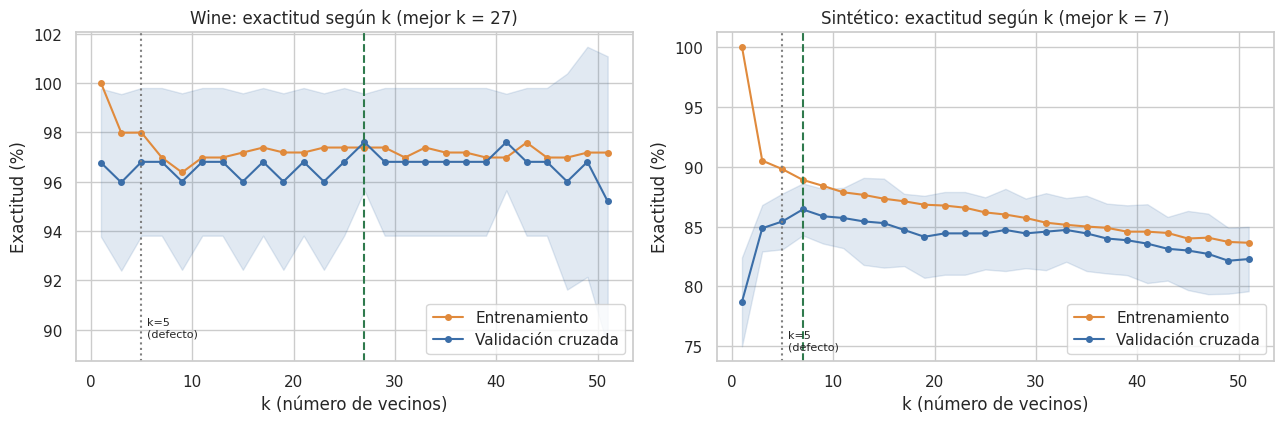

Mejor k según la curva de validación: {'Wine': 27, 'Sintético': 7}


In [52]:
valores_k = list(range(1, 52, 2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
mejor_k_curva = {}
for ax, (nombre_ds, (X, y)) in zip(axes, datasets.items()):
    X_tr, _, y_tr, _ = dividir_holdout(X, y)
    ent, val = validation_curve(pipeline_knn(), X_tr, y_tr, param_name="knn__k", param_range=valores_k,
                                cv=obtener_kfold(), scoring="accuracy")
    ent_m, val_m, val_s = 100 * ent.mean(axis=1), 100 * val.mean(axis=1), 100 * val.std(axis=1)
    mejor_k_curva[nombre_ds] = valores_k[int(np.argmax(val_m))]
    ax.plot(valores_k, ent_m, "o-", color="#E08A3C", ms=4, label="Entrenamiento")
    ax.plot(valores_k, val_m, "o-", color="#3B6EA8", ms=4, label="Validación cruzada")
    ax.fill_between(valores_k, val_m - val_s, val_m + val_s, color="#3B6EA8", alpha=0.15)
    ax.axvline(5, color="gray", ls=":", lw=1.5); ax.text(5.5, ax.get_ylim()[0] + 1, "k=5\n(defecto)", fontsize=8)
    ax.axvline(mejor_k_curva[nombre_ds], color="#2F7A4D", ls="--", lw=1.5)
    ax.set_title(f"{nombre_ds}: exactitud según k (mejor k = {mejor_k_curva[nombre_ds]})")
    ax.set_xlabel("k (número de vecinos)"); ax.set_ylabel("Exactitud (%)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Mejor k según la curva de validación:", mejor_k_curva)

**Lectura de la curva:**
- **k = 1 sobreajusta:** la exactitud de entrenamiento es 100 % (cada muestra es su propio vecino más cercano), pero en
  validación cae, sobre todo en el sintético (78.7 %), porque con un solo vecino el modelo copia el ruido: si ese
  vecino tiene una de las etiquetas alteradas, se equivoca.
- **k muy grande subajusta:** en el sintético, después de k ≈ 7–9 la exactitud baja poco a poco, porque el voto
  incluye vecinos lejanos que ya pertenecen a otras clases.
- **En Wine la curva es casi plana:** entre k = 3 y k = 49 la validación se mueve entre 96 % y 97.6 %, dentro de la
  franja de variación entre folds. El "mejor k = 27" no es claramente mejor que k = 5; la diferencia es de un par de
  muestras.
- **En el sintético el máximo está en k = 7**, muy cerca del valor por defecto (k = 5).

## 10.3 Búsqueda en rejilla con Hold Out

`GridSearchCV` prueba las 64 combinaciones con validación cruzada de 5 folds **sobre el 70 % de entrenamiento**, elige
la mejor y la reentrena con todo el entrenamiento. Después se mide una sola vez en el 30 % de prueba y se compara con
K-NN con parámetros por defecto en la misma partición.

In [53]:
filas_opt, mejores_parametros, busquedas = [], {}, {}
for nombre_ds, (X, y) in datasets.items():
    X_tr, X_te, y_tr, y_te = dividir_holdout(X, y)
    busqueda = GridSearchCV(pipeline_knn(), REJILLA_KNN, cv=obtener_kfold(), scoring="accuracy", n_jobs=-1)
    t0 = time.perf_counter(); busqueda.fit(X_tr, y_tr); t_busqueda = time.perf_counter() - t0
    busquedas[nombre_ds] = busqueda
    mejores = {k.replace("knn__", ""): v for k, v in busqueda.best_params_.items()}
    mejores_parametros[nombre_ds] = mejores

    defecto = pipeline_knn().fit(X_tr, y_tr)
    filas_opt.append({"dataset": nombre_ds,
                      "mejores parámetros": f"k={mejores['k']}, {mejores['metrica']}, {mejores['pesos']}",
                      "CV interna defecto %": 100 * busqueda.cv_results_["mean_test_score"][
                          busqueda.cv_results_["params"].index({"knn__k": 5, "knn__metrica": "euclidiana",
                                                                "knn__pesos": "uniforme"})],
                      "CV interna mejor %": 100 * busqueda.best_score_,
                      "prueba defecto %": 100 * defecto.score(X_te, y_te),
                      "prueba optimizado %": 100 * busqueda.score(X_te, y_te),
                      "tiempo búsqueda s": t_busqueda})
optimizacion_ho = pd.DataFrame(filas_opt)
optimizacion_ho.round(2)

,dataset,mejores parámetros,CV interna defecto %,CV interna mejor %,prueba defecto %,prueba optimizado %,tiempo búsqueda s
0,Wine,"k=5, manhattan, uniforme",96.80,99.20,94.44,98.15,3.6
1,Sintético,"k=7, euclidiana, uniforme",85.43,86.43,82.33,82.33,5.7


In [54]:
# Las 5 mejores combinaciones de cada dataset (segun la validacion cruzada interna)
for nombre_ds, busqueda in busquedas.items():
    top = (pd.DataFrame(busqueda.cv_results_)
           .sort_values("rank_test_score")
           [["param_knn__k", "param_knn__metrica", "param_knn__pesos", "mean_test_score", "std_test_score"]]
           .head(5))
    top.columns = ["k", "métrica", "pesos", "exactitud CV", "desv. CV"]
    top[["exactitud CV", "desv. CV"]] = (100 * top[["exactitud CV", "desv. CV"]].astype(float)).round(2)
    print(f"===== {nombre_ds} =====")
    display(top.reset_index(drop=True))

===== Wine =====


,k,métrica,pesos,exactitud CV,desv. CV
0,5,manhattan,uniforme,99.2,1.6
1,5,manhattan,distancia,99.2,1.6
2,3,manhattan,uniforme,97.6,4.8
3,3,manhattan,distancia,97.6,4.8
4,7,manhattan,distancia,97.6,3.2


===== Sintético =====


,k,métrica,pesos,exactitud CV,desv. CV
0,7,euclidiana,uniforme,86.43,2.17
1,7,euclidiana,distancia,86.43,2.26
2,9,manhattan,distancia,86.43,3.10
3,7,manhattan,distancia,86.29,2.65
4,9,manhattan,uniforme,86.29,3.18


## 10.4 K-Fold con optimización anidada

Para comparar de forma justa con el K-NN por defecto en K-Fold, la búsqueda se repite **dentro de cada uno de los 5
folds** (validación cruzada anidada): en cada ronda, `GridSearchCV` elige los parámetros usando solo los 4 folds de
entrenamiento y después se mide en el fold de prueba. Así el fold de prueba nunca participa en la elección.

In [55]:
filas_anidada, elegidos = [], []
for nombre_ds, (X, y) in datasets.items():
    exact_def, exact_opt = [], []
    for f, (tr, te) in enumerate(obtener_kfold().split(X, y), start=1):
        interna = GridSearchCV(pipeline_knn(), REJILLA_KNN, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA),
                               scoring="accuracy", n_jobs=-1).fit(X[tr], y[tr])
        exact_opt.append(100 * interna.score(X[te], y[te]))
        exact_def.append(100 * pipeline_knn().fit(X[tr], y[tr]).score(X[te], y[te]))
        p = interna.best_params_
        elegidos.append({"dataset": nombre_ds, "fold": f, "k": p["knn__k"], "métrica": p["knn__metrica"],
                         "pesos": p["knn__pesos"], "exactitud fold %": round(exact_opt[-1], 2)})
    filas_anidada.append({"dataset": nombre_ds,
                          "defecto %": np.mean(exact_def), "defecto desv": np.std(exact_def),
                          "optimizado %": np.mean(exact_opt), "optimizado desv": np.std(exact_opt),
                          "mejora (puntos)": np.mean(exact_opt) - np.mean(exact_def)})

optimizacion_kf = pd.DataFrame(filas_anidada)
display(optimizacion_kf.round(2))
print("Parámetros elegidos en cada fold:")
pd.DataFrame(elegidos)

,dataset,defecto %,defecto desv,optimizado %,optimizado desv,mejora (puntos)
0,Wine,97.17,1.81,97.19,2.52,0.02
1,Sintético,85.60,1.88,85.60,1.24,0.00


Parámetros elegidos en cada fold:


,dataset,fold,k,métrica,pesos,exactitud fold %
0,Wine,1,27,euclidiana,uniforme,94.44
1,Wine,2,21,euclidiana,uniforme,97.22
2,Wine,3,7,manhattan,uniforme,100.00
3,Wine,4,5,manhattan,uniforme,94.29
4,Wine,5,25,euclidiana,uniforme,100.00
5,Sintético,1,7,manhattan,uniforme,87.50
6,Sintético,2,7,manhattan,distancia,84.50
7,Sintético,3,9,manhattan,uniforme,86.00
8,Sintético,4,7,manhattan,distancia,86.00
9,Sintético,5,5,euclidiana,uniforme,84.00


## 10.5 Resumen: parámetros por defecto contra optimizados

,dataset,parámetros elegidos (Hold Out),Hold Out defecto %,Hold Out optimizado %,K-Fold defecto %,K-Fold optimizado %
0,Wine,"k=5, manhattan, uniforme",94.44,98.15,97.17,97.19
1,Sintético,"k=7, euclidiana, uniforme",82.33,82.33,85.60,85.60


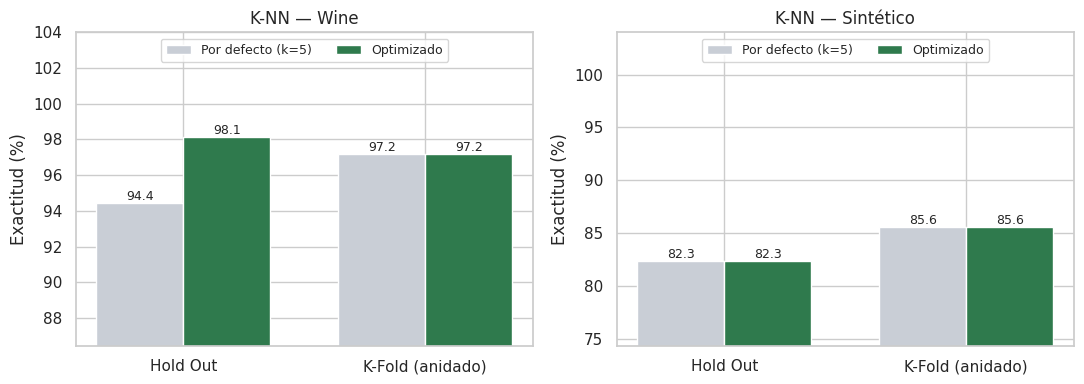

In [56]:
resumen_opt = []
for nombre_ds in datasets:
    ho = optimizacion_ho.set_index("dataset").loc[nombre_ds]
    kf = optimizacion_kf.set_index("dataset").loc[nombre_ds]
    resumen_opt.append({"dataset": nombre_ds, "parámetros elegidos (Hold Out)": ho["mejores parámetros"],
                        "Hold Out defecto %": ho["prueba defecto %"], "Hold Out optimizado %": ho["prueba optimizado %"],
                        "K-Fold defecto %": kf["defecto %"], "K-Fold optimizado %": kf["optimizado %"]})
resumen_opt = pd.DataFrame(resumen_opt)
display(resumen_opt.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nombre_ds in zip(axes, datasets):
    r = resumen_opt.set_index("dataset").loc[nombre_ds]
    x = np.arange(2); ancho = 0.36
    b1 = ax.bar(x - ancho / 2, [r["Hold Out defecto %"], r["K-Fold defecto %"]], ancho, color="#C9CED6",
                label="Por defecto (k=5)")
    b2 = ax.bar(x + ancho / 2, [r["Hold Out optimizado %"], r["K-Fold optimizado %"]], ancho, color="#2F7A4D",
                label="Optimizado")
    ax.bar_label(b1, fmt="%.1f", fontsize=9); ax.bar_label(b2, fmt="%.1f", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(["Hold Out", "K-Fold (anidado)"])
    piso = min(r["Hold Out defecto %"], r["K-Fold defecto %"], r["Hold Out optimizado %"], r["K-Fold optimizado %"])
    ax.set_ylim(piso - 8, 104); ax.set_ylabel("Exactitud (%)"); ax.set_title(f"K-NN — {nombre_ds}")
    ax.legend(loc="upper center", ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

### ¿Mejoran los resultados?

**Muy poco o nada.** Los parámetros por defecto de K-NN ya están prácticamente en el óptimo para estos dos datasets:

- **Wine, Hold Out:** la búsqueda eligió `k=5`, distancia **Manhattan** y votación uniforme, y la exactitud de prueba
  subió de 94.44 % a 98.15 % (2 muestras más bien clasificadas de 54). Sin embargo, con **K-Fold anidado** la mejora
  desaparece: 97.17 % contra 97.19 %. La ganancia del Hold Out se debe en buena parte a esa partición particular.
- **Sintético:** la búsqueda eligió `k=7`, euclidiana, uniforme; en Hold Out la exactitud quedó igual (82.33 %) y en
  K-Fold anidado también (85.60 % en ambos casos). Lo único que mejora es la estabilidad: la desviación entre folds
  baja de 1.88 a 1.24.
- **Los parámetros elegidos cambian de un fold a otro** (en Wine, k va de 5 a 27 y la métrica alterna entre
  euclidiana y Manhattan). Eso indica que muchas combinaciones dan resultados casi iguales: la "superficie" de
  exactitud es plana y no hay una combinación claramente superior.

Esto es un resultado válido e importante para el reporte: **probar otros parámetros no siempre mejora el modelo**, y
una mejora en una sola partición Hold Out puede ser casualidad. Solo una validación más robusta (K-Fold anidado) lo
puede confirmar.

### ¿Cómo encontrar los mejores parámetros para cada dataset?

1. **Definir una rejilla** de valores razonables para cada hiperparámetro (aquí 64 combinaciones).
2. **Evaluar cada combinación con validación cruzada solo sobre el entrenamiento** (`GridSearchCV`), con la
   normalización dentro de un `Pipeline` para evitar fuga de datos.
3. **Medir la combinación elegida una sola vez en el conjunto de prueba**, o mejor aún, usar **validación cruzada
   anidada** para estimar de forma honesta cuánto mejora.
4. Usar **curvas de validación** (como la de 10.2) para entender el efecto de cada parámetro y detectar sobreajuste
   (k pequeño) o subajuste (k grande).
5. Si la rejilla es muy grande, usar **búsqueda aleatoria** (`RandomizedSearchCV`), que prueba solo una muestra de
   combinaciones.

Los mejores parámetros **dependen de cada dataset** (Wine prefirió Manhattan; el sintético, k = 7), por eso la
búsqueda se hace por separado para cada uno.

# 11. Comparación de los seis clasificadores

Tabla integrada con los resultados de los tres integrantes (sección 9.4), con parámetros base. Se toma **K-Fold como
referencia principal**, porque promedia 5 particiones y es más estable que el Hold Out.

In [57]:
orden_modelos = [m[0] for m in MODELOS_EQUIPO]
kf = resultados_equipo[resultados_equipo["validacion"].str.startswith("K-Fold")]
ho = resultados_equipo[resultados_equipo["validacion"].str.startswith("Hold")]

def tabla_dataset(nombre_ds):
    a = kf[kf["dataset"] == nombre_ds].set_index("modelo")
    b = ho[ho["dataset"] == nombre_ds].set_index("modelo")
    t = pd.DataFrame({
        "integrante": a["integrante"],
        "K-Fold exactitud": [f"{m:.2f} ± {s:.2f}" for m, s in zip(a["exactitud"], a["exactitud_std"])],
        "K-Fold F1": a["f1"].round(2),
        "Hold Out exactitud": b["exactitud"].round(2),
        "Hold Out F1": b["f1"].round(2),
        "t_fit_ms": a["t_fit_ms"].round(3),
        "t_pred_ms": a["t_pred_ms"].round(3),
    }).loc[orden_modelos]
    t["lugar (K-Fold)"] = a.loc[orden_modelos, "exactitud"].rank(ascending=False, method="min").astype(int)
    return t

for nombre_ds in datasets:
    print(f"==================== {nombre_ds} ====================")
    display(tabla_dataset(nombre_ds))

==================== Wine ====================


,integrante,K-Fold exactitud,K-Fold F1,Hold Out exactitud,Hold Out F1,t_fit_ms,t_pred_ms,lugar (K-Fold)
modelo,,,,,,,,
Distancia Mínima,Integrante 1,97.75 ± 2.13,97.79,98.15,98.11,0.177,0.077,3
1-NN,Integrante 2,95.51 ± 2.23,95.56,96.30,96.36,0.005,1.118,6
K-NN (k=5),Integrante 3,97.17 ± 1.81,97.21,94.44,94.41,0.047,5.893,5
Naïve Bayes,Integrante 3,97.19 ± 2.52,97.32,100.00,100.00,1.495,1.287,4
SVM,Integrante 2,98.33 ± 2.22,98.34,98.15,98.08,3.055,0.959,1
MLP,Integrante 1,97.76 ± 1.12,97.71,100.00,100.00,518.861,0.570,2


==================== Sintético ====================


,integrante,K-Fold exactitud,K-Fold F1,Hold Out exactitud,Hold Out F1,t_fit_ms,t_pred_ms,lugar (K-Fold)
modelo,,,,,,,,
Distancia Mínima,Integrante 1,70.20 ± 3.08,70.19,72.33,72.17,0.685,0.119,6
1-NN,Integrante 2,79.60 ± 1.98,79.56,79.67,79.66,0.005,18.390,4
K-NN (k=5),Integrante 3,85.60 ± 1.88,85.57,82.33,82.31,0.073,18.084,2
Naïve Bayes,Integrante 3,75.30 ± 3.98,75.35,75.67,75.69,1.480,0.418,5
SVM,Integrante 2,84.90 ± 1.36,84.93,84.00,84.01,14.213,4.488,3
MLP,Integrante 1,87.40 ± 0.86,87.33,84.00,83.99,2831.953,0.510,1


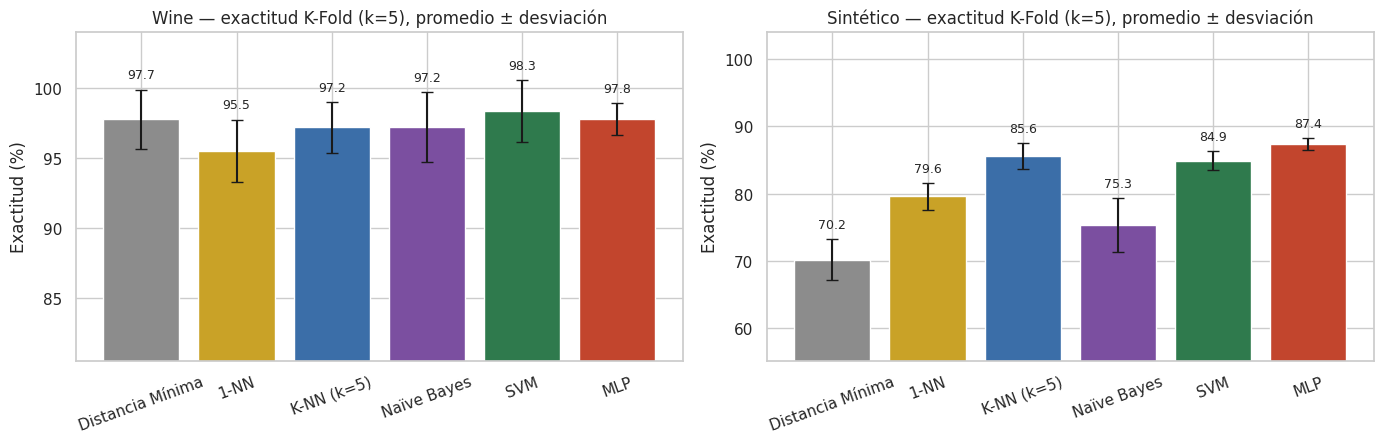

In [58]:
colores = ["#8C8C8C", "#C9A227", "#3B6EA8", "#7B4FA0", "#2F7A4D", "#C2452D"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, nombre_ds in zip(axes, datasets):
    a = kf[kf["dataset"] == nombre_ds].set_index("modelo").loc[orden_modelos]
    barras = ax.bar(orden_modelos, a["exactitud"], yerr=a["exactitud_std"], capsize=4, color=colores)
    ax.bar_label(barras, fmt="%.1f", padding=6, fontsize=9)
    ax.set_ylim(max(0, a["exactitud"].min() - 15), 104)
    ax.set_title(f"{nombre_ds} — exactitud K-Fold (k=5), promedio ± desviación")
    ax.set_ylabel("Exactitud (%)"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### Observaciones

**Wine (dataset "fácil"):**
- Los seis clasificadores quedan entre **95.5 % y 98.3 %** en K-Fold. El mejor es SVM (98.33 %) y el último 1-NN
  (95.51 %), pero las diferencias son menores que la desviación entre folds (alrededor de ±2 puntos), así que **no hay
  un ganador claro**.
- Distancia Mínima, el modelo más simple, obtiene 97.75 %, prácticamente lo mismo que el MLP (97.76 %). Las clases de
  Wine están tan bien separadas que un centroide por clase basta.

**Sintético (dataset "difícil", con ruido estructurado):**
- Aquí sí hay diferencias grandes: de **70.2 % a 87.4 %**. Gana el **MLP (87.40 %)**, seguido de **K-NN (85.60 %)** y
  **SVM (84.90 %)**. Los tres son modelos **flexibles**, capaces de formar fronteras de decisión no lineales.
- Los que suponen una estructura simple quedan al final: **Naïve Bayes (75.30 %)**, que supone características
  independientes, y **Distancia Mínima (70.20 %)**, que supone que cada clase se resume en un solo centro.
- **1-NN (79.60 %) queda 6 puntos debajo de K-NN (85.60 %).** Con 5 % de etiquetas alteradas, usar un solo vecino
  copia el ruido; votar entre varios vecinos lo compensa.

**Costo contra exactitud:**
- K-NN queda segundo en el sintético con un entrenamiento de unos 0.03 ms, mientras que el MLP, primero, tarda más de
  un segundo por fold. A cambio, K-NN es de los más lentos al predecir.
- Ningún modelo es el mejor en todo: el desempeño depende del dataset, y el modelo más complejo no siempre es el más
  conveniente.

# 12. Complejidad temporal (10 de noviembre)

La complejidad temporal describe **cómo crece el tiempo de un algoritmo cuando crecen los datos**. Se usa la notación
$O(\cdot)$, que indica el orden de crecimiento ignorando constantes: por ejemplo, $O(n)$ significa que si se duplica
$n$, el tiempo aproximadamente se duplica, y $O(n^2)$ que se cuadruplica.

Notación:

| Símbolo | Significado |
|---|---|
| $n$ | número de muestras de entrenamiento |
| $m$ | número de muestras a predecir |
| $d$ | número de características |
| $c$ | número de clases |
| $k$ | número de vecinos (K-NN) |
| $n_{sv}$ | número de vectores de soporte (SVM), $n_{sv} \le n$ |
| $h$ | neuronas en la capa oculta (MLP; por defecto 100) |
| $E$ | número de épocas de entrenamiento (MLP) |

## 12.1 Análisis teórico de los seis clasificadores

| Clasificador | Entrenamiento | Predicción de $m$ muestras | Qué domina el costo |
|---|---|---|---|
| Distancia Mínima | $O(n\,d)$ | $O(m\,c\,d)$ | Calcular un centroide por clase; predecir compara solo contra $c$ centroides |
| 1-NN | $O(1)$ (solo guarda; memoria $O(n\,d)$) | $O(m\,n\,d)$ | Distancia a todas las muestras de entrenamiento |
| K-NN | $O(1)$ para guardar (memoria $O(n\,d)$) + $O(n \log n)$ para listar las clases | $O(m\,n\,d + m\,n + m\,k \log k)$ = $O(m\,n\,d)$ | Distancias; elegir los $k$ menores con `argpartition` es lineal en $n$ |
| Naïve Bayes Gaussiano | $O(n\,d)$ | $O(m\,c\,d)$ | Una media y una varianza por clase y característica |
| SVM (kernel RBF) | entre $O(n^2 d)$ y $O(n^3 d)$ | $O(m\,n_{sv}\,d)$ | Resolver el problema de optimización con la matriz de kernel $n \times n$ |
| MLP (1 capa oculta) | $O(E\,n\,(d\,h + h\,c))$ | $O(m\,(d\,h + h\,c))$ | Propagar y retropropagar cada muestra en cada época |

### Detalle de K-NN (implementación propia)

1. `fit`: guarda `X_train` y `y_train` → $O(1)$ en tiempo (solo se guardan referencias) y $O(n\,d)$ en memoria.
   Además obtiene la lista de clases con `np.unique`, que cuesta $O(n \log n)$ pero tarda microsegundos.
2. Matriz de distancias euclidianas con $\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a\cdot b$ →
   el producto `X @ X_train.T` cuesta $O(m\,n\,d)$.
3. `argpartition` para encontrar los $k$ más cercanos de cada muestra → $O(n)$ por muestra, $O(m\,n)$ en total.
4. Ordenar solo esos $k$ → $O(k \log k)$ por muestra.
5. Votación → $O(k)$ por muestra.

Total de predicción: $O(m\,n\,d)$. Como $k$ es pequeño comparado con $n$, **el valor de $k$ casi no afecta el
tiempo**; lo que pesa es el tamaño del entrenamiento.

### Detalle de Naïve Bayes Gaussiano

1. `fit`: para cada clase calcula la media y la varianza de cada característica → recorre los datos una vez:
   $O(n\,d)$.
2. `predict`: para cada muestra y cada clase suma $d$ términos de log-verosimilitud → $O(m\,c\,d)$.
   **No depende de $n$**: el modelo solo guarda $2\,c\,d + c$ números, sin importar cuántas muestras se usaron.

## 12.2 Comprobación experimental: K-NN y Naïve Bayes

Se generan datasets sintéticos de distintos tamaños con `make_classification` y se mide el tiempo real. Cada medición
se repite 5 veces y se toma la mediana para reducir el ruido.

En una gráfica con ambos ejes logarítmicos, un algoritmo $O(n^p)$ aparece como una recta de pendiente $p$. Por eso se
estima la **pendiente** de cada curva con los tamaños más grandes: una pendiente cercana a 1 indica crecimiento lineal y
una cercana a 0, que el tiempo no cambia.

En K-NN se miden por separado:
- **búsqueda de vecinos** (`kvecinos`: distancias + selección de los $k$ menores), que es la parte $O(m\,n\,d)$, y
- **predicción completa** (`predict`), que además incluye la votación. La votación está escrita con un ciclo de Python
  por muestra; cuesta $O(m\,k)$, no depende de $n$, pero en tamaños chicos su costo fijo pesa bastante.

Se usan tamaños grandes (hasta 64,000 muestras) porque con pocos datos el tiempo lo dominan costos fijos (llamadas a
funciones, validaciones de Scikit-learn), y entonces la pendiente sale menor que la teórica. Esta celda tarda
alrededor de un minuto.

In [59]:
def medir(funcion, repeticiones=5):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter(); funcion(); tiempos.append(time.perf_counter() - t0)
    return 1000 * np.median(tiempos)   # ms

def datos_complejidad(n, d, m=200, semilla=SEMILLA):
    X, y = make_classification(n_samples=n + m, n_features=d, n_informative=max(3, d // 2),
                               n_redundant=0, n_classes=3, random_state=semilla)
    return X[:n], y[:n], X[n:]

def medir_modelos(n, d, m=200):
    X_tr, y_tr, X_te = datos_complejidad(n, d, m)
    knn = KNNDesdeCero(k=5).fit(X_tr, y_tr)
    nb = GaussianNB().fit(X_tr, y_tr)
    return {"K-NN fit": medir(lambda: KNNDesdeCero(k=5).fit(X_tr, y_tr)),
            "K-NN vecinos": medir(lambda: knn.kvecinos(X_te)),
            "K-NN predict": medir(lambda: knn.predict(X_te)),
            "NB fit": medir(lambda: GaussianNB().fit(X_tr, y_tr)),
            "NB predict": medir(lambda: nb.predict(X_te))}

# Experimento A: variar n (muestras de entrenamiento) con d = 10 y m = 200 fijos
valores_n = [1000, 2000, 4000, 8000, 16000, 32000, 64000]
exp_n = pd.DataFrame([{"n": n, **medir_modelos(n, d=10)} for n in valores_n])

# Experimento B: variar d (caracteristicas) con n = 4000 y m = 200 fijos
valores_d = [10, 20, 40, 80, 160, 320, 640]
exp_d = pd.DataFrame([{"d": d, **medir_modelos(4000, d)} for d in valores_d])

display(exp_n.round(3)); display(exp_d.round(3))

,n,K-NN fit,K-NN vecinos,K-NN predict,NB fit,NB predict
0,1000,0.057,5.102,27.030,3.783,0.413
1,2000,0.098,19.336,33.733,4.437,0.450
2,4000,0.185,24.266,46.632,3.719,0.388
3,8000,0.380,31.040,44.547,5.602,0.359
4,16000,0.733,58.534,72.870,9.916,0.349
5,32000,0.971,148.933,160.393,11.675,0.254
6,64000,2.312,278.018,278.974,23.311,0.257


,d,K-NN fit,K-NN vecinos,K-NN predict,NB fit,NB predict
0,10,0.129,12.727,29.943,3.220,0.348
1,20,0.188,14.154,26.653,3.539,0.379
2,40,0.195,13.709,27.239,3.925,0.405
3,80,0.183,16.216,31.437,5.231,0.526
4,160,0.201,21.598,39.701,8.420,0.682
5,320,0.203,30.552,46.844,15.065,1.450
6,640,0.129,55.026,63.962,29.990,1.793


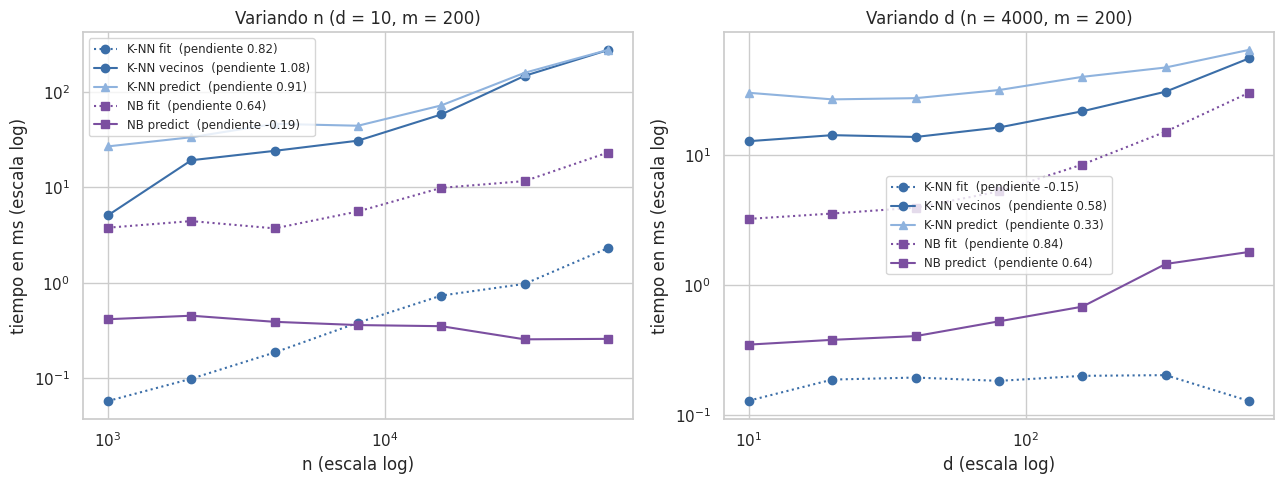

,operación,pendiente respecto a n,teoría (n),pendiente respecto a d,teoría (d),R² lineal (d)
0,K-NN fit,0.82,≈ 0 (solo np.unique),-0.15,0 (no depende),0.126
1,K-NN vecinos,1.08,1 (lineal),0.58,1 (lineal),0.994
2,K-NN predict,0.91,1 (lineal),0.33,1 (lineal),0.978
3,NB fit,0.64,1 (lineal),0.84,1 (lineal),0.997
4,NB predict,-0.19,0 (no depende),0.64,1 (lineal),0.940


In [60]:
def pendiente(x, t, ultimos=4):
    # Pendiente en escala log-log usando solo los tamanos mas grandes (los chicos los dominan costos fijos)
    x, t = np.asarray(x[-ultimos:], float), np.asarray(t[-ultimos:], float)
    return np.polyfit(np.log(x), np.log(t), 1)[0]

columnas = ["K-NN fit", "K-NN vecinos", "K-NN predict", "NB fit", "NB predict"]
estilos = {"K-NN fit": ("#3B6EA8", ":", "o"), "K-NN vecinos": ("#3B6EA8", "-", "o"),
           "K-NN predict": ("#8FB3DE", "-", "^"),
           "NB fit": ("#7B4FA0", ":", "s"), "NB predict": ("#7B4FA0", "-", "s")}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, df_exp, var, titulo in [(axes[0], exp_n, "n", "Variando n (d = 10, m = 200)"),
                                (axes[1], exp_d, "d", "Variando d (n = 4000, m = 200)")]:
    for col in columnas:
        color, ls, mk = estilos[col]
        ax.plot(df_exp[var], df_exp[col], ls=ls, marker=mk, color=color,
                label=f"{col}  (pendiente {pendiente(df_exp[var], df_exp[col]):.2f})")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{var} (escala log)"); ax.set_ylabel("tiempo en ms (escala log)")
    ax.set_title(titulo); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

pendientes = pd.DataFrame({
    "operación": columnas,
    "pendiente respecto a n": [round(pendiente(exp_n["n"], exp_n[c]), 2) for c in columnas],
    "teoría (n)": ["≈ 0 (solo np.unique)", "1 (lineal)", "1 (lineal)", "1 (lineal)", "0 (no depende)"],
    "pendiente respecto a d": [round(pendiente(exp_d["d"], exp_d[c]), 2) for c in columnas],
    "teoría (d)": ["0 (no depende)", "1 (lineal)", "1 (lineal)", "1 (lineal)", "1 (lineal)"],
})

def r2_lineal(x, t):
    # Que tan bien se ajusta una recta t = a + b*x (en escala normal). Cerca de 1 = crecimiento lineal
    x, t = np.asarray(x, float), np.asarray(t, float)
    pred = np.polyval(np.polyfit(x, t, 1), x)
    return 1 - np.sum((t - pred) ** 2) / np.sum((t - t.mean()) ** 2)

pendientes["R² lineal (d)"] = [round(r2_lineal(exp_d["d"], exp_d[c]), 3) for c in columnas]
pendientes

**Lectura de los resultados** (los tiempos exactos cambian según la computadora, pero las tendencias se mantienen):

- **Respecto a n:**
  - La búsqueda de vecinos de K-NN crece de forma aproximadamente **lineal** con $n$ (pendiente cercana o un poco
    mayor que 1). Al duplicar las muestras de entrenamiento, predecir tarda aproximadamente el doble. La pendiente
    puede salir algo mayor que 1 en los tamaños más grandes porque las matrices de distancias ya no caben en la
    memoria rápida (caché) del procesador.
  - El entrenamiento de Naïve Bayes también crece con $n$ (pendiente cercana a 1 en los tamaños grandes).
  - La **predicción de Naïve Bayes no cambia con $n$** (pendiente ≈ 0): tarda lo mismo con 1,000 que con 64,000
    muestras de entrenamiento, porque solo usa las medias y varianzas guardadas. Esta es la diferencia más importante
    entre los dos modelos.
  - El entrenamiento de K-NN tarda centésimas de milisegundo en todos los tamaños: solo guarda los datos. Su tiempo
    crece un poco con $n$ únicamente por `np.unique`, que obtiene la lista de clases ($O(n \log n)$), pero aun con
    64,000 muestras sigue por debajo de 0.1 ms, miles de veces menos que predecir.
- **Respecto a d:** todos los tiempos (salvo `fit` de K-NN) crecen al aumentar $d$, pero la pendiente log-log sale
  menor que 1. No significa que el crecimiento sea menor que lineal: hay costos que no dependen de $d$ (en K-NN, la
  raíz cuadrada, `argpartition` y la votación, que son $O(m\,n)$ y $O(m\,k)$) y que pesan más cuando $d$ es pequeño.
  El ajuste de una recta $t = a + b\,d$ en escala normal tiene un **R² cercano a 1**, lo que confirma que el tiempo
  crece de forma lineal con $d$ más un costo fijo.
- **Conclusión:** las mediciones coinciden con el análisis teórico. K-NN traslada todo el costo a la predicción y ese
  costo crece con el tamaño del entrenamiento; Naïve Bayes hace un trabajo pequeño al entrenar y predice en un tiempo
  que no depende de cuántos datos se usaron para entrenar.

## 12.3 Tiempos medidos de los seis clasificadores

Tiempos promedio por fold del K-Fold de la sección 9.4 (escala logarítmica, porque las diferencias entre modelos son de
varios órdenes de magnitud).

t_fit_ms          t_pred_ms       
dataset          Sintético     Wine Sintético   Wine
modelo                                              
Distancia Mínima     0.685    0.177     0.119  0.077
1-NN                 0.005    0.005    18.390  1.118
K-NN (k=5)           0.073    0.047    18.084  5.893
Naïve Bayes          1.480    1.495     0.418  1.287
SVM                 14.213    3.055     4.488  0.959
MLP               2831.953  518.861     0.510  0.570

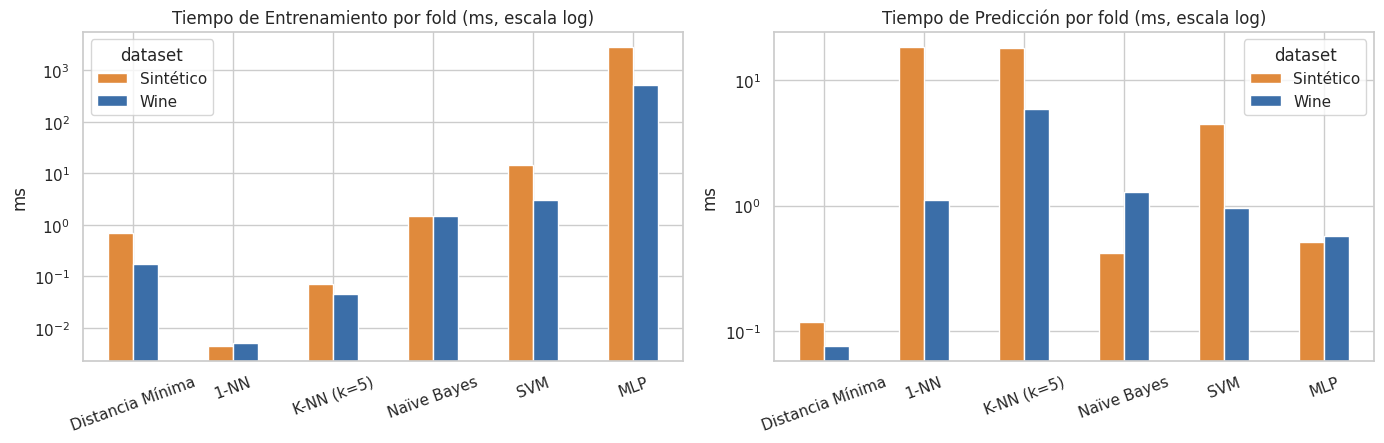

In [61]:
t = kf.pivot_table(index="modelo", columns="dataset", values=["t_fit_ms", "t_pred_ms"]).loc[orden_modelos]
display(t.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, col, titulo in [(axes[0], "t_fit_ms", "Entrenamiento"), (axes[1], "t_pred_ms", "Predicción")]:
    datos = kf.pivot_table(index="modelo", columns="dataset", values=col).loc[orden_modelos]
    datos.plot(kind="bar", ax=ax, color=["#E08A3C", "#3B6EA8"], logy=True, rot=20)
    ax.set_title(f"Tiempo de {titulo} por fold (ms, escala log)"); ax.set_xlabel(""); ax.set_ylabel("ms")
plt.tight_layout(); plt.show()

**Lectura:**
- **Entrenamiento:** 1-NN y K-NN son los más rápidos (solo guardan los datos), seguidos de Distancia Mínima y Naïve
  Bayes (un recorrido de los datos). SVM y MLP son los más costosos. Del Wine al sintético, el número de muestras de
  entrenamiento crece unas 5.6 veces (de 142 a 800) y el entrenamiento de SVM crece en una proporción igual o mayor,
  como se espera de una complejidad al menos lineal (con datasets tan pequeños los costos fijos todavía pesan, así que
  no alcanza para confirmar el orden cuadrático). El MLP es por mucho el más lento (más de un segundo por fold en el
  sintético).
- **Predicción:** se invierte el orden. 1-NN y K-NN son de los más lentos porque comparan cada muestra contra todo el
  entrenamiento. Del Wine al sintético, el producto $m\,n\,d$ crece unas 14 veces (de 36 × 142 × 13 a 200 × 800 × 6),
  y el tiempo de predicción de 1-NN crece alrededor de un orden de magnitud (unas 10 veces), consistente con
  $O(m\,n\,d)$. Distancia Mínima y Naïve Bayes predicen casi en
  el mismo tiempo en ambos datasets, porque solo comparan contra $c = 3$ resúmenes por clase.
- Esto confirma la tabla teórica de 12.1: **los métodos perezosos (1-NN y K-NN) son baratos al entrenar y caros al
  predecir; SVM y MLP son lo contrario.**

# 13. Conclusiones

1. **Divisiones comunes verificadas.** Los tres integrantes usan exactamente las mismas particiones de Hold Out y de
   K-Fold, y los resultados de los compañeros se reproducen al 100 % con su propio código. Por lo tanto, la
   comparación de los seis clasificadores es justa.
2. **El dataset importa más que el modelo cuando los datos son fáciles.** En Wine, los seis modelos quedan entre
   95.5 % y 98.3 % y sus diferencias caben dentro de la variación entre folds. En el sintético, con ruido estructurado
   y etiquetas alteradas, la diferencia entre el mejor y el peor es de 17 puntos.
3. **Los modelos flexibles resisten mejor el ruido.** En el sintético ganan MLP (87.4 %), K-NN (85.6 %) y SVM (84.9 %);
   Naïve Bayes (75.3 %) y Distancia Mínima (70.2 %) quedan atrás porque sus suposiciones (independencia y un solo
   centro por clase) no se cumplen.
4. **K-NN es una opción muy competitiva:** segundo lugar en el sintético y a poco más de 1 punto del mejor en Wine, con un
   entrenamiento prácticamente instantáneo. Votar entre varios vecinos es mejor que usar solo uno: K-NN supera a 1-NN
   por 6 puntos en el sintético.
5. **Naïve Bayes funciona muy bien cuando sus suposiciones se cumplen** (97.2 % en Wine, empatado con K-NN) y es el más
   rápido para predecir junto con Distancia Mínima, pero es el menos estable y el que más pierde con características
   correlacionadas.
6. **Optimizar K-NN no mejoró los resultados de forma confirmable.** La mejora de 3.7 puntos en el Hold Out de Wine
   desaparece con K-Fold anidado; en el sintético no hubo cambio. Los valores por defecto (k = 5) ya están cerca del
   óptimo. La forma correcta de buscar parámetros es con validación cruzada solo sobre el entrenamiento
   (`GridSearchCV`) y estimar la mejora con validación cruzada anidada.
7. **K-Fold es más confiable que Hold Out**, sobre todo con pocos datos: en Wine un solo Hold Out puede variar varios
   puntos según qué muestras caigan en la prueba (por ejemplo, Naïve Bayes 100 % en Hold Out contra 97.2 % en K-Fold).
8. **Complejidad:** K-NN tiene entrenamiento $O(1)$ y predicción $O(m\,n\,d)$; Naïve Bayes, entrenamiento $O(n\,d)$ y
   predicción $O(m\,c\,d)$, independiente de $n$. Las mediciones experimentales confirman ambos comportamientos. Para
   datasets muy grandes, K-NN se vuelve costoso al predecir, mientras que Naïve Bayes escala muy bien.

**Repositorio del código:** https://github.com/paolamrk/Practica3_MachineLearning